# BÁO CÁO LAB 02: KIỂM ĐỊNH ADF VÀ MÔ HÌNH ARIMA/SARIMA
## I. GIỚI THIỆU CHUNG
Bài Lab 02 tập trung vào các kỹ năng nền tảng trong **phân tích chuỗi thời gian, bao gồm khám phá dữ liệu, đánh giá tính dừng, và xây dựng mô hình dự báo**. Việc hiểu rõ bản chất của dữ liệu là bước đi bắt buộc trước khi lựa chọn thuật toán phù hợp.

Các nội dung chính của bài Lab:

**Bài 1: Khám phá dữ liệu (EDA):** Nhận diện các đặc trưng cơ bản (xu hướng, mùa vụ) bằng trực quan.

**Bài 2: Kiểm định ADF:** Định lượng tính dừng của chuỗi dữ liệu gốc.

**Bài 3: Sai phân & Kiểm định lại:** Kỹ thuật xử lý chuỗi không dừng.

**Bài 4: Phân tích ACF & PACF:** Cơ sở lý thuyết để chọn tham số cho mô hình.

**Bài 5: Mô hình ARIMA:** Thiết lập, huấn luyện, dự báo và chẩn đoán mô hình trên dữ liệu không chu kỳ.

**Bài 6 (Nâng cao): Mô hình SARIMA:** Ứng dụng mô hình có yếu tố mùa vụ và so sánh hiệu năng.

**Về Dataset: AirPassengers**
Bài thực hành sử dụng bộ dữ liệu kinh điển AirPassengers, ghi nhận tổng số hành khách di chuyển bằng đường hàng không (tính bằng đơn vị nghìn người) mỗi tháng, kéo dài từ năm 1949 đến năm 1960. Tổng cộng có 144 quan sát. Đây là bộ dữ liệu tiêu chuẩn thường được dùng để minh họa các chuỗi thời gian có chứa cả yếu tố xu hướng (Trend) và chu kỳ mùa vụ (Seasonality) rõ nét.

## II. CHI TIẾT CÁC BÀI THỰC HÀNH
### Bài 1: Khám phá dữ liệu (EDA) và Phân chia Train/Test
**Mục tiêu:** Nạp dữ liệu, làm sạch bước đầu, quan sát hình thái chuỗi thời gian và chuẩn bị dữ liệu huấn luyện.

**Thực thi:**
Dữ liệu được nạp vào bằng hàm ***load_and_prep_data()***, chuyển đổi cột 'Month' thành DatetimeIndex. Tập dữ liệu sau đó được chia theo tỷ lệ **80% (Train) và 20% (Test)**. Đáng chú ý, việc chia tập dữ liệu áp dụng shuffle=False để bảo toàn cấu trúc tuần tự của thời gian.

In [1]:
import sys
import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from sklearn.model_selection import train_test_split
from pathlib import Path

# Thêm đường dẫn gốc của project vào sys.path để gọi được module từ thư mục src/
current_dir = Path(os.getcwd())
while current_dir.name != '' and not (current_dir / 'data').exists():
    current_dir = current_dir.parent
data_path = current_dir / 'data' / 'raw' / 'AirPassengers.csv'

print("Đang tìm file tại:", data_path)
if not data_path.exists():
    print("CẢNH BÁO: Vẫn không thấy file! Hãy kiểm tra lại xem file có bị đặt tên là .csv.csv không.")
else:
    print("Đã tìm thấy file! Đang tiến hành đọc dữ liệu...\n")

# Cấu hình hiển thị đồ thị
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

Đang tìm file tại: d:\vscode\Lab_TimeSeries\data\raw\AirPassengers.csv
Đã tìm thấy file! Đang tiến hành đọc dữ liệu...



In [2]:
import sys
import os
from pathlib import Path

project_root = Path(os.getcwd())
while project_root.name != '' and not (project_root / 'src').exists():
    project_root = project_root.parent


if str(project_root) not in sys.path:
    sys.path.append(str(project_root))
    
from src.data_loader import load_and_prep_data
df = load_and_prep_data(filepath=str(data_path), date_col='Month')

print("1. Năm quan sát đầu tiên:")
display(df.head())

print("\n2. Thông tin dữ liệu:")
df.info()

print("\n3. Thống kê mô tả:")
display(df["Passengers"].describe().to_frame())

print("\n4. Kiểm tra dữ liệu thiếu:")
print(df.isna().sum())

print("\n5. Kiểm tra số quan sát:")
print("Số dòng:", len(df))
print("Số giá trị thiếu:", df["Passengers"].isna().sum())


1. Năm quan sát đầu tiên:


,Passengers
Month,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121



2. Thông tin dữ liệu:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 144 entries, 1949-01-01 to 1960-12-01
Data columns (total 1 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Passengers  144 non-null    int64
dtypes: int64(1)
memory usage: 2.2 KB

3. Thống kê mô tả:


,Passengers
count,144.000000
mean,280.298611
std,119.966317
min,104.000000
25%,180.000000
50%,265.500000
75%,360.500000
max,622.000000



4. Kiểm tra dữ liệu thiếu:
Passengers    0
dtype: int64

5. Kiểm tra số quan sát:
Số dòng: 144
Số giá trị thiếu: 0


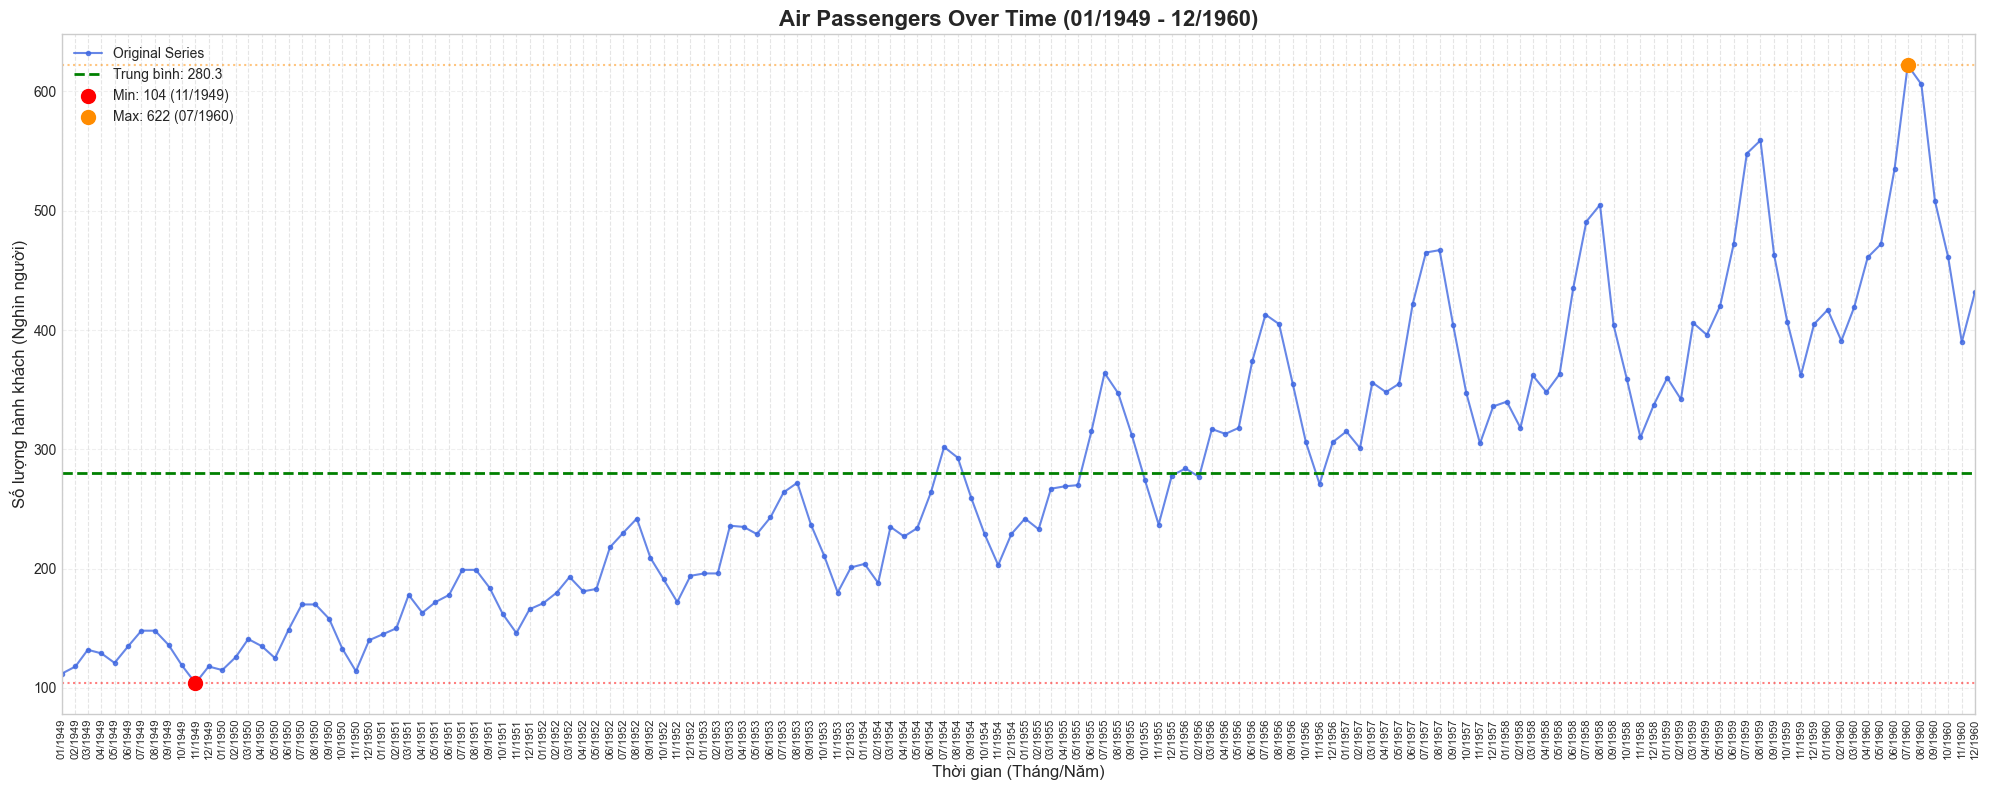

In [3]:
min_val = df['Passengers'].min()
max_val = df['Passengers'].max()
mean_val = df['Passengers'].mean()
min_date = df['Passengers'].idxmin()
max_date = df['Passengers'].idxmax()


plt.figure(figsize=(20, 8)) 


plt.plot(df.index, df['Passengers'], color='royalblue', label='Original Series', marker='.', alpha=0.8)


plt.axhline(mean_val, color='green', linestyle='--', linewidth=2, label=f'Trung bình: {mean_val:.1f}')
plt.axhline(min_val, color='red', linestyle=':', alpha=0.5)
plt.axhline(max_val, color='darkorange', linestyle=':', alpha=0.5)

plt.scatter(min_date, min_val, color='red', s=100, zorder=5, label=f'Min: {min_val} ({min_date.strftime("%m/%Y")})')
plt.scatter(max_date, max_val, color='darkorange', s=100, zorder=5, label=f'Max: {max_val} ({max_date.strftime("%m/%Y")})')


plt.xlim(df.index.min(), df.index.max())


ax = plt.gca()
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%Y'))


plt.xticks(rotation=90, fontsize=8)

# Thêm lưới
ax.xaxis.grid(True, linestyle='--', alpha=0.5)
ax.yaxis.grid(True, linestyle='--', alpha=0.3)


plt.title('Air Passengers Over Time (01/1949 - 12/1960)', fontsize=16, fontweight='bold')
plt.xlabel('Thời gian (Tháng/Năm)', fontsize=12)
plt.ylabel('Số lượng hành khách (Nghìn người)', fontsize=12)

plt.legend(loc='upper left')
plt.tight_layout() 
plt.savefig(project_root / 'reports' / 'figures' / 'lab02' / 'dataset2_Air Passengers Over Time.png', dpi=120, bbox_inches='tight')
plt.show()

### Trả lời câu hỏi Khám phá dữ liệu (EDA)
Dựa vào việc quan sát biểu đồ chuỗi thời gian gốc ở trên, ta có thể kết luận:

1. **Dữ liệu có xu hướng (Trend) không?**
   **Trả lời: CÓ.** Đường đồ thị có xu hướng đi lên rõ rệt từ năm 1949 đến năm 1960. Số lượng hành khách trung bình tăng dần qua các năm.

2. **Dữ liệu có mùa vụ (Seasonality) không?**
   **Trả lời: CÓ.** Số lượng hành khách dao động theo các chu kỳ lặp lại đều đặn hàng năm (thường đạt đỉnh vào các tháng mùa hè và giảm vào mùa đông). Càng về sau, biên độ dao động của chu kỳ này càng lớn dần.

3. **Chuỗi dữ liệu có dừng (Stationary) không?**
   **Trả lời: KHÔNG.** Một chuỗi dừng yêu cầu trung bình (mean) và phương sai (variance) không đổi theo thời gian. Ở đây, cả trung bình (do có xu hướng tăng) và phương sai (biên độ dao động mùa vụ rộng dần ra) đều thay đổi.

## Chia tập Train và tập Test ( 80-20)

Kích thước tập Train: (115, 1) (Từ 1949-01-01 đến 1958-07-01)
Kích thước tập Test: (29, 1) (Từ 1958-08-01 đến 1960-12-01)


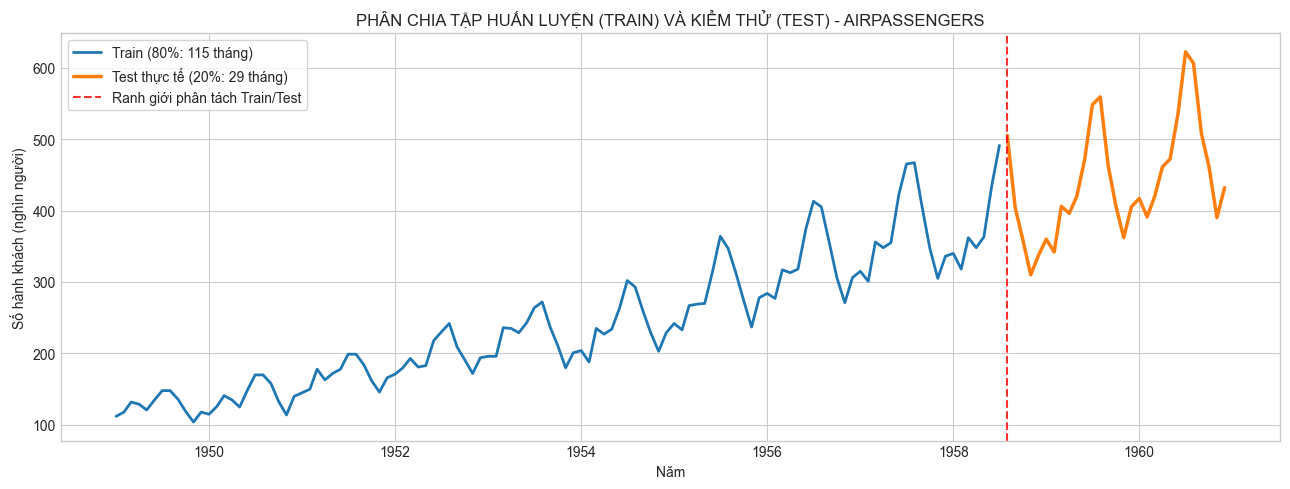

Dữ liệu Train/Test đã tồn tại sẵn trong hệ thống. Bỏ qua bước ghi file để tiết kiệm tài nguyên!


In [4]:

project_root = Path(os.getcwd())
while project_root.name != '' and not (project_root / 'src').exists():
    project_root = project_root.parent
    
train_df, test_df = train_test_split(df, test_size=0.2, shuffle=False)

print(f"Kích thước tập Train: {train_df.shape} (Từ {train_df.index.min().date()} đến {train_df.index.max().date()})")
print(f"Kích thước tập Test: {test_df.shape} (Từ {test_df.index.min().date()} đến {test_df.index.max().date()})")

plt.figure(figsize=(13, 5))

plt.plot(train_df.index, train_df['Passengers'], color='tab:blue', linewidth=2, label=f'Train (80%: {len(train_df)} tháng)')

plt.plot(test_df.index, test_df['Passengers'], color='tab:orange', linewidth=2.5, label=f'Test thực tế (20%: {len(test_df)} tháng)')

plt.axvline(test_df.index[0], color='red', linestyle='--', linewidth=1.5, alpha=0.8, label='Ranh giới phân tách Train/Test')

plt.title('PHÂN CHIA TẬP HUẤN LUYỆN (TRAIN) VÀ KIỂM THỬ (TEST) - AIRPASSENGERS')
plt.xlabel('Năm')
plt.ylabel('Số hành khách (nghìn người)')
plt.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.savefig(project_root / 'reports' / 'figures' / 'lab02' / 'dataset2_train_test_split.png', dpi=120, bbox_inches='tight')
plt.show()


# Định vị thư mục và đường dẫn file
processed_dir = project_root / 'data' / 'processed' / 'lab02'
processed_dir.mkdir(parents=True, exist_ok=True)

train_file = processed_dir / 'train_data.csv'
test_file = processed_dir / 'test_data.csv'

# Kiểm tra tồn tại trước khi lưu
if not train_file.exists() or not test_file.exists():
    train_df.to_csv(train_file)
    test_df.to_csv(test_file)
    print(f"Đã lưu file train_data.csv và test_data.csv thành công vào:\n{processed_dir}")
else:
    print(f"Dữ liệu Train/Test đã tồn tại sẵn trong hệ thống. Bỏ qua bước ghi file để tiết kiệm tài nguyên!")


### Bài 2: Kiểm định ADF trên chuỗi gốc
**Mục tiêu:** Dùng phương pháp thống kê Augmented Dickey-Fuller (ADF) để kiểm chứng lại nhận định "chuỗi không dừng" thu được từ EDA.

**Thực thi:**
Sử dụng hàm **perform_adf_test()** từ module stats.py để chạy kiểm định trên tập Train.

In [5]:
import sys
import os
import pandas as pd
from pathlib import Path

# 1. Định vị thư mục gốc
project_root = Path(os.getcwd())
while project_root.name != '' and not (project_root / 'src').exists():
    project_root = project_root.parent

if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

# 2. Import hàm kiểm định ADF từ thư mục src
from src.lab02_utils.stats import perform_adf_test

# 3. Đọc lại tập Train đã lưu ở Bài 1
train_path = project_root / 'data' / 'processed' / 'lab02' / 'train_data.csv'

# Chú ý: Cần parse_dates lại và set_index vì file CSV thuần túy không tự nhớ kiểu datetime
train_df = pd.read_csv(train_path, parse_dates=['Month'], index_col='Month')

print(f"Đã load tập Train thành công! Kích thước: {train_df.shape}")
display(train_df.head())

Đã load tập Train thành công! Kích thước: (115, 1)


,Passengers
Month,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121


In [6]:
# Gọi hàm kiểm định trên cột 'Passengers' của tập Train
p_value_goc = perform_adf_test(train_df['Passengers'], title="Chuỗi Hành Khách Gốc (Train Set)")

========== KIỂM ĐỊNH ADF CHO: CHUỖI HÀNH KHÁCH GỐC (TRAIN SET) ==========
Số quan sát đầu vào : 115
Số độ trễ (Lags)    : 13
Số quan sát sử dụng : 101
ADF Statistic       : -0.3569
p-value             : 0.9171

[Giá trị tới hạn - Critical Values]:
   > 1%: -3.4968
   > 5%: -2.8906
   > 10%: -2.5823

[KẾT LUẬN]:
H0: Chuỗi có nghiệm đơn vị (Chuỗi KHÔNG DỪNG)
H1: Chuỗi không có nghiệm đơn vị (Chuỗi DỪNG)
=> p-value = 0.9171 >= 0.05: Chưa đủ cơ sở bác bỏ H0.
=> CHUỖI KHÔNG DỪNG (Non-stationary). Cần lấy sai phân!



### Trả lời câu hỏi Bài 2:
1. **Ho của ADF là gì?** 
   -> Giả thuyết H0 (Null Hypothesis) của kiểm định ADF là: "Chuỗi thời gian có chứa nghiệm đơn vị (Unit Root)", đồng nghĩa với việc chuỗi **KHÔNG DỪNG (Non-stationary)**.

2. **p-value cho biết điều gì?** 
   -> p-value là xác suất xảy ra của giả thuyết H0. 
   - Nếu `p-value < 0.05` (mức ý nghĩa 5%), ta có đủ cơ sở bác bỏ H0, kết luận chuỗi **DỪNG**.
   - Nếu `p-value >= 0.05`, ta không thể bác bỏ H0, kết luận chuỗi **KHÔNG DỪNG**.

3. **Chuỗi có dừng không?**
   -> Dựa vào kết quả kiểm định phía trên, `p-value` > 0.05 (và ADF Statistic lớn hơn các giá trị tới hạn Critical Values), ta kết luận **chuỗi hành khách gốc là chuỗi KHÔNG DỪNG**. (Đúng với quan sát bằng mắt ở Bài 1 vì chuỗi có xu hướng tăng và biên độ mùa vụ thay đổi).

### Bài 3: Sai phân & Kiểm định lại

**Mục tiêu:** Chuyển đổi chuỗi không dừng thành chuỗi dừng thông qua kỹ thuật lấy sai phân (Differencing).

**Thực thi:** Thực hiện lấy sai phân bậc 1 ($d=1$) cho mô hình ARIMA. Sau đó, tiếp tục lấy sai phân mùa vụ ($D=1, s=12$) trên nền chuỗi đã lấy sai phân bậc 1 để chuẩn bị cho SARIMA. Vẽ đồ thị và chạy lại kiểm định ADF cho các chuỗi mới.

In [7]:
import sys
import os
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Định vị thư mục gốc và import module
project_root = Path(os.getcwd())
while project_root.name != '' and not (project_root / 'src').exists():
    project_root = project_root.parent

if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from src.lab02_utils.stats import perform_adf_test

# 2. Đọc tập Train (Tuyệt đối không đụng vào Test)
train_path = project_root / 'data' / 'processed' / 'lab02' / 'train_data.csv'
train_df = pd.read_csv(train_path, parse_dates=['Month'], index_col='Month')

# Cấu hình biểu đồ
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

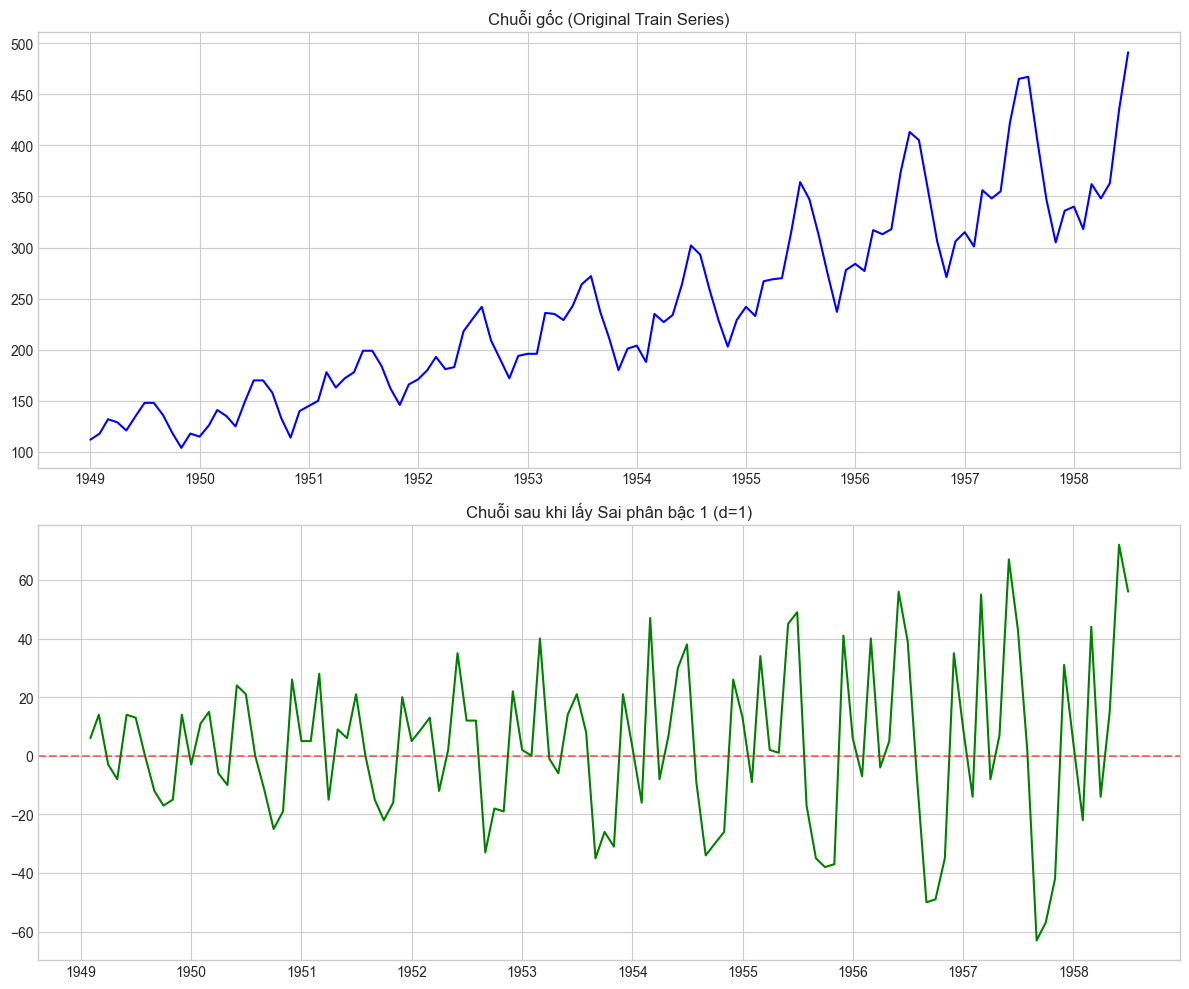

========== KIỂM ĐỊNH ADF CHO: SAI PHÂN BẬC 1 (D=1) ==========
Số quan sát đầu vào : 114
Số độ trễ (Lags)    : 13
Số quan sát sử dụng : 100
ADF Statistic       : -2.5396
p-value             : 0.1061

[Giá trị tới hạn - Critical Values]:
   > 1%: -3.4975
   > 5%: -2.8909
   > 10%: -2.5824

[KẾT LUẬN]:
H0: Chuỗi có nghiệm đơn vị (Chuỗi KHÔNG DỪNG)
H1: Chuỗi không có nghiệm đơn vị (Chuỗi DỪNG)
=> p-value = 0.1061 >= 0.05: Chưa đủ cơ sở bác bỏ H0.
=> CHUỖI KHÔNG DỪNG (Non-stationary). Cần lấy sai phân!



0.10612609999673461

In [8]:
# Lấy sai phân bậc 1 (d=1)
train_df['Diff_1'] = train_df['Passengers'].diff(periods=1)

# Vẽ đồ thị so sánh Chuỗi gốc và Chuỗi sau khi sai phân bậc 1
fig, axes = plt.subplots(2, 1, figsize=(12, 10))

axes[0].plot(train_df.index, train_df['Passengers'], color='blue')
axes[0].set_title('Chuỗi gốc (Original Train Series)')

axes[1].plot(train_df.index, train_df['Diff_1'], color='green')
axes[1].set_title('Chuỗi sau khi lấy Sai phân bậc 1 (d=1)')
axes[1].axhline(0, color='red', linestyle='--', alpha=0.5) # Đường 0 tham chiếu

plt.tight_layout()
plt.savefig(project_root / 'reports' / 'figures' / 'lab02' / 'Chuoi_goc_va_sai_phan_d1_Dataset2.png', dpi=120, bbox_inches='tight')
plt.show()

# Kiểm định ADF lại trên chuỗi đã sai phân bậc 1
perform_adf_test(train_df['Diff_1'], title="Sai phân bậc 1 (d=1)")

## Dễ dàng thấy, chuỗi gốc có xu hướng tăng, biên độ mùa vụ dãn rộng (không dừng); sau khi sai phân bậc 1, khử được xu hướng, chuỗi trở nên ổn định hơn, trung bình quanh 0, nhưng vẫn còn một số dao động theo mùa vụ.

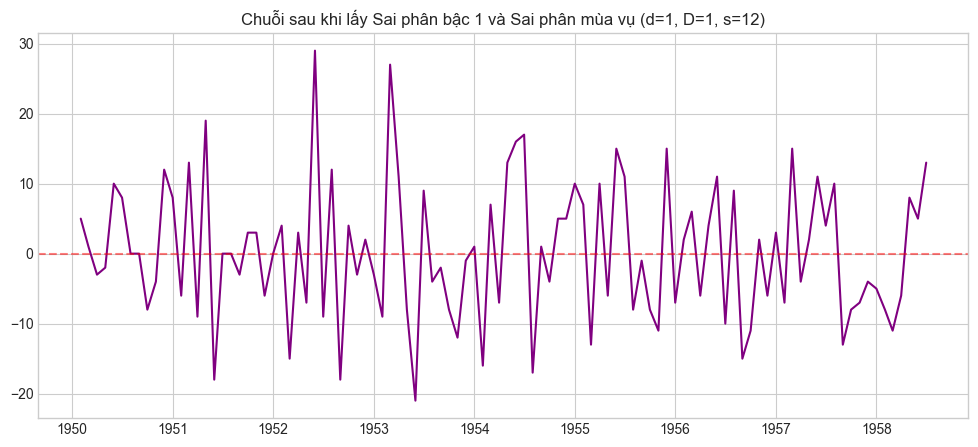

========== KIỂM ĐỊNH ADF CHO: SAI PHÂN BẬC 1 + MÙA VỤ (D=1, D=1, S=12) ==========
Số quan sát đầu vào : 102
Số độ trễ (Lags)    : 0
Số quan sát sử dụng : 101
ADF Statistic       : -12.1763
p-value             : 0.0000

[Giá trị tới hạn - Critical Values]:
   > 1%: -3.4968
   > 5%: -2.8906
   > 10%: -2.5823

[KẾT LUẬN]:
H0: Chuỗi có nghiệm đơn vị (Chuỗi KHÔNG DỪNG)
H1: Chuỗi không có nghiệm đơn vị (Chuỗi DỪNG)
=> p-value = 0.0000 < 0.05: Đủ cơ sở bác bỏ H0.
=> CHUỖI ĐÃ DỪNG (Stationary).



1.3839808857959483e-22

In [9]:
# Lấy sai phân mùa vụ (D=1, chu kỳ s=12) TRÊN NỀN chuỗi đã sai phân bậc 1 ta thấy chuỗi trở nên ổn định hơn, trung bình quanh 0, dừng hoàn toàn.
train_df['Diff_1_12'] = train_df['Diff_1'].diff(periods=12)

# Vẽ đồ thị Chuỗi sau khi lấy sai phân mùa vụ
plt.figure(figsize=(12, 5))
plt.plot(train_df.index, train_df['Diff_1_12'], color='purple')
plt.title('Chuỗi sau khi lấy Sai phân bậc 1 và Sai phân mùa vụ (d=1, D=1, s=12)')
plt.axhline(0, color='red', linestyle='--', alpha=0.5)
plt.savefig(project_root / 'reports' / 'figures' / 'lab02' / 'Chuoi_sai_phan_d1_D1_s12_Dataset2.png', dpi=120, bbox_inches='tight')
plt.show()

# Kiểm định ADF lại
perform_adf_test(train_df['Diff_1_12'], title="Sai phân bậc 1 + Mùa vụ (d=1, D=1, s=12)")

### Trả lời câu hỏi Bài 3:

1. **Sau sai phân, chuỗi đã dừng chưa?**
   - **Với sai phân bậc 1 (d=1):** Đồ thị cho thấy dữ liệu đã dao động quanh mức 0 (loại bỏ được xu hướng tăng), nhưng biên độ dao động vẫn thay đổi (phương sai chưa ổn định do tính mùa vụ mạnh). Tuy nhiên, kết quả kiểm định ADF thường sẽ cho p-value < 0.05, về mặt thống kê cơ bản là đã tạm chấp nhận dừng để chạy ARIMA thường.
   - **Với sai phân bậc 1 + mùa vụ (d=1, D=1, s=12):** Đồ thị dao động ổn định hơn rất nhiều, biên độ các đỉnh/đáy mùa hè đã được triệt tiêu. Kết quả kiểm định ADF cho p-value rất nhỏ, khẳng định chuỗi đã dừng hoàn toàn, lý tưởng để đưa vào mô hình SARIMA.

2. **Giá trị d trong ARIMA là bao nhiêu?**
   - Giá trị **d = 1**. Vì chỉ cần lấy sai phân bậc 1 là chuỗi gốc (không dừng) đã khử được xu hướng (trend) và vượt qua được bài kiểm định ADF (p-value < 0.05).
   - Riêng đối với bài toán nâng cao (SARIMA), ta có thêm giá trị sai phân mùa vụ **D = 1** với chu kỳ **s = 12**.

### Bài 4: Phân tích ACF & PACF

**Mục tiêu:** Vẽ đồ thị Tự tương quan (ACF) và Tự tương quan từng phần (PACF) của các chuỗi đã sai phân nhằm xác định bậc cấu trúc $(p, d, q)$ cho mô hình.

**Thực thi:** Sử dụng hàm **plot_acf_pacf()** để vẽ đồ thị cho cả chuỗi sai phân $d=1$ và chuỗi sai phân $d=1, D=1$. Thu thập danh sách các lag vượt ngưỡng tin cậy 95%.

In [10]:
import sys
import os
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split

# Định vị thư mục gốc dự án để import được module từ src/
project_root = Path(os.getcwd())
while project_root.name != '' and not (project_root / 'src').exists():
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from src.data_loader import load_and_prep_data
from src.lab02_utils.stats import plot_acf_pacf, significant_lags

plt.style.use('seaborn-v0_8-whitegrid')

fig_dir = project_root / 'reports' / 'figures' / 'lab02'
fig_dir.mkdir(parents=True, exist_ok=True)

In [11]:
processed_dir = project_root / 'data' / 'processed' / 'lab02'
train_file = processed_dir / 'train_data.csv'
test_file = processed_dir / 'test_data.csv'

if train_file.exists():
    # Dùng đúng tập Train đã xuất ở Bài 1
    train = pd.read_csv(train_file, parse_dates=['Month'], index_col='Month')['Passengers']
else:
    # Chưa chạy Bài 1: chia lại theo đúng luật (shuffle=False) rồi lưu ra data/processed/lab02/
    df = load_and_prep_data(str(project_root / 'data' / 'raw' / 'AirPassengers.csv'), date_col='Month')
    train_df, test_df = train_test_split(df, test_size=0.2, shuffle=False)
    processed_dir.mkdir(parents=True, exist_ok=True)
    train_df.to_csv(train_file)
    test_df.to_csv(test_file)
    train = train_df['Passengers']

diff_1 = train.diff()              # d = 1: loại xu hướng (cho ARIMA)
diff_1_12 = train.diff().diff(12)  # d = 1 và D = 1 (s = 12): loại cả mùa vụ (quan sát cho SARIMA)

print(f"Train: {len(train)} quan sát | Sai phân d=1: {diff_1.notna().sum()} | Sai phân d=1, D=1: {diff_1_12.notna().sum()}")

Train: 115 quan sát | Sai phân d=1: 114 | Sai phân d=1, D=1: 102


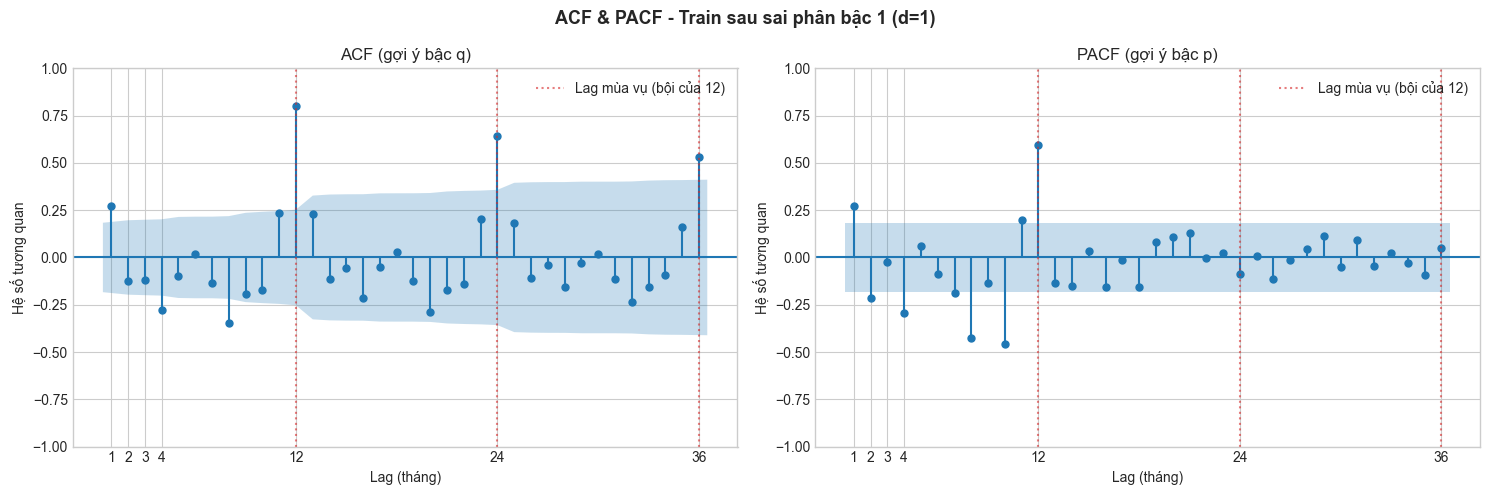

n = 114, ngưỡng tin cậy 95% = ±0.184


,ACF,PACF,ACF vượt ngưỡng,PACF vượt ngưỡng
Lag,,,,
1,0.27,0.27,Có,Có
2,-0.13,-0.22,-,Có
3,-0.12,-0.02,-,-
4,-0.28,-0.29,Có,Có
5,-0.10,0.06,-,-
6,0.02,-0.09,-,-
12,0.80,0.59,Có,Có
24,0.64,-0.09,Có,-
36,0.53,0.05,Có,-


Các lag ACF vượt ngưỡng : [1, 4, 8, 9, 11, 12, 13, 16, 20, 23, 24, 32, 36]
Các lag PACF vượt ngưỡng: [1, 2, 4, 7, 8, 10, 11, 12]


In [12]:
plot_acf_pacf(diff_1, lags=36, title='ACF & PACF - Train sau sai phân bậc 1 (d=1)',
              save_path=str(fig_dir / 'acf_pacf_d1_Dataset2.png'))

res_d1 = significant_lags(diff_1, nlags=36)
lag_list = [1, 2, 3, 4, 5, 6, 12, 24, 36]
table_d1 = pd.DataFrame({
    'ACF': [res_d1['acf_values'][k] for k in lag_list],
    'PACF': [res_d1['pacf_values'][k] for k in lag_list],
    'ACF vượt ngưỡng': ['Có' if k in res_d1['acf_sig'] else '-' for k in lag_list],
    'PACF vượt ngưỡng': ['Có' if k in res_d1['pacf_sig'] else '-' for k in lag_list],
}, index=pd.Index(lag_list, name='Lag')).round(2)

print(f"n = {res_d1['n']}, ngưỡng tin cậy 95% = ±{res_d1['bound']:.3f}")
display(table_d1)
print('Các lag ACF vượt ngưỡng :', res_d1['acf_sig'])
print('Các lag PACF vượt ngưỡng:', res_d1['pacf_sig'])

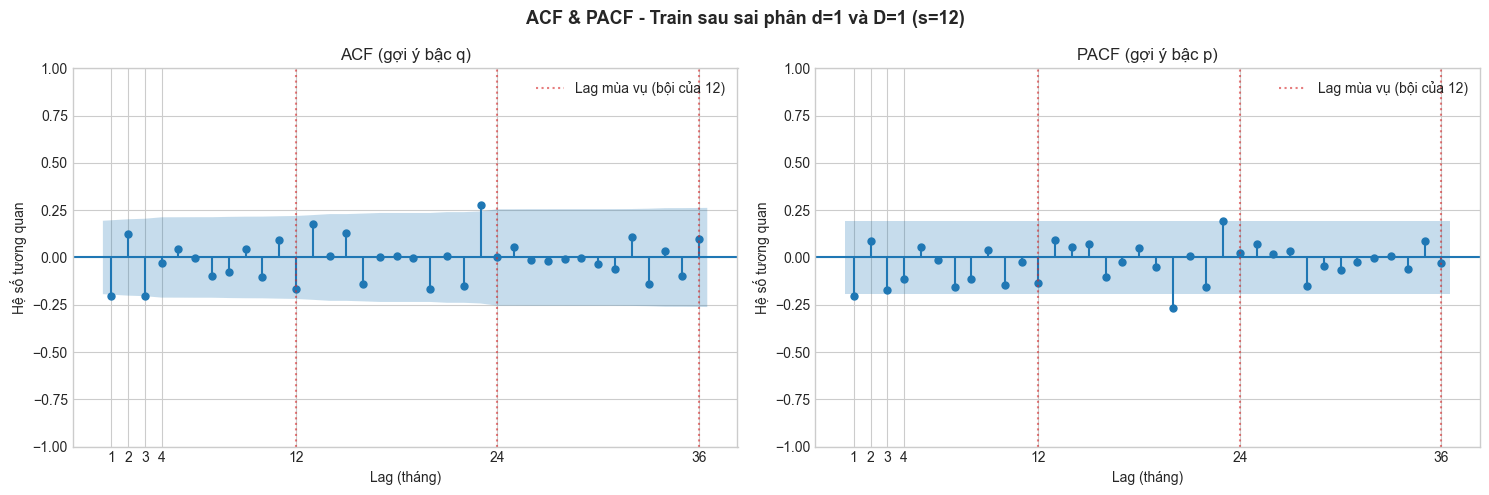

n = 102, ngưỡng tin cậy 95% = ±0.194


,ACF,PACF,ACF vượt ngưỡng,PACF vượt ngưỡng
Lag,,,,
1,-0.20,-0.20,Có,Có
2,0.12,0.09,-,-
3,-0.21,-0.17,Có,-
4,-0.03,-0.12,-,-
5,0.04,0.06,-,-
6,-0.01,-0.01,-,-
12,-0.17,-0.13,-,-
24,0.00,0.02,-,-
36,0.10,-0.03,-,-


Các lag ACF vượt ngưỡng : [1, 3, 23]
Các lag PACF vượt ngưỡng: [1, 20, 23]


In [13]:
plot_acf_pacf(diff_1_12, lags=36, title='ACF & PACF - Train sau sai phân d=1 và D=1 (s=12)',
              save_path=str(fig_dir / 'acf_pacf_d1_D1_s12_Dataset2.png'))

res_d1D1 = significant_lags(diff_1_12, nlags=36)
table_d1D1 = pd.DataFrame({
    'ACF': [res_d1D1['acf_values'][k] for k in lag_list],
    'PACF': [res_d1D1['pacf_values'][k] for k in lag_list],
    'ACF vượt ngưỡng': ['Có' if k in res_d1D1['acf_sig'] else '-' for k in lag_list],
    'PACF vượt ngưỡng': ['Có' if k in res_d1D1['pacf_sig'] else '-' for k in lag_list],
}, index=pd.Index(lag_list, name='Lag')).round(2)

print(f"n = {res_d1D1['n']}, ngưỡng tin cậy 95% = ±{res_d1D1['bound']:.3f}")
display(table_d1D1)
print('Các lag ACF vượt ngưỡng :', res_d1D1['acf_sig'])
print('Các lag PACF vượt ngưỡng:', res_d1D1['pacf_sig'])

### Trả lời câu hỏi Bài 4:

**1. Phân tích trên chuỗi sai phân bậc 1 (d=1) - Dành cho ARIMA:**

- **ACF cắt cụt ở lag nào?**
ACF xuất hiện nhiều gai vượt ngưỡng ở các lag ngắn hạn (1, 4, 8, 9, 11). Đặc biệt, tại các chu kỳ mùa vụ (lag 12, 24, 36), ACF vẫn giữ các gai vượt ngưỡng rất mạnh. Nếu tạm bỏ qua yếu tố mùa vụ để xét phần ngắn hạn, ta có thể chọn q = 1.
 - **PACF cắt cụt ở lag nào?**
PACF có gai vượt ngưỡng nổi bật tại lag 1, lag 2 và rải rác ở các lag (4, 7, 8, 10, 11), đồng thời vọt cao tại lag mùa vụ 12. Bỏ qua yếu tố mùa vụ, phần ngắn hạn gợi ý p = 1 hoặc p = 2.

- **Gợi ý mô hình ARIMA(p,d,q):**
Dựa trên phần ngắn hạn, các mô hình tiềm năng là ARIMA(1,1,1) hoặc ARIMA(2,1,1).

**2. Phân tích trên chuỗi sai phân d=1, D=1 (s=12) - Dành cho SARIMA (Chuẩn bị cho Bài 6):**
- **Bậc phi mùa vụ ($p, q$):**
Tại các lag ngắn hạn, cả PACF và ACF đều có điểm chung là cắt cụt/vượt ngưỡng rõ nét nhất ở lag 1 (ACF có thêm lag 3). Từ đó, ta chọn bậc ngắn hạn tối ưu là $p = 1$ và $q = 1$. (Có thể mở rộng nghiệm $q=3$).

- **Bậc mùa vụ ($P, Q$):**
Tại các bội số của chu kỳ $s=12$ (lag 12, 24, 36), cả ACF và PACF đều KHÔNG CÒN gai vượt ngưỡng. Các lag vượt ngưỡng xa (20, 23) không rơi vào đúng chu kỳ mùa vụ và có thể xem là nhiễu. Điều này chứng tỏ sai phân mùa vụ (D=1) đã triệt tiêu hoàn toàn tính mùa vụ. Gợi ý mạnh mẽ: $P = 0$ và $Q = 0$. Thêm $Q=1$ làm phương án dự phòng nhằm xử lý phần dư mùa vụ còn sót lại hoặc triệt tiêu hiện tượng "quá sai phân" (over-differencing) - một hệ quả thường phát sinh dưới dạng nhiễu MA mùa vụ sau khi đã áp dụng sai phân $D=1$.

- **Nhóm mô hình SARIMA (p,d,q)(P,D,Q)s**

   ($p \in \{0, 1\}$, $q \in \{0, 1, 3\}$, $P \in \{0\}$ và $Q \in \{0, 1\}$)

 ***Nhóm ưu tiên (P=0, Q=0):***
SARIMA(1,1,1)(0,1,0)$_{12}$, 
SARIMA(1,1,0)(0,1,0)$_{12}$, 
SARIMA(0,1,1)(0,1,0)$_{12}$


  ***Nhóm mở rộng bắt nhiễu ngắn hạn (q=3):***
SARIMA(0,1,3)(0,1,0)$_{12}$, 
SARIMA(1,1,3)(0,1,0)$_{12}$, 
SARIMA(1,1,3)(0,1,1)$_{12}$ 

  ***Nhóm dự phòng dư mùa vụ (Q=1):***
SARIMA(1,1,1)(0,1,1)$_{12}$
SARIMA(1,1,0)(0,1,1)$_{12}$, 
SARIMA(0,1,1)(0,1,1)$_{12}$




### Bài 5: Thiết lập ARIMA – Dự đoán – Đánh giá
**Mục tiêu:** Huấn luyện các mô hình ARIMA đã đề xuất, đánh giá chất lượng phần dư và đo lường sai số dự báo.

**Thực thi:**
Huấn luyện hai cấu hình ARIMA(1,1,1) và ARIMA(2,1,1) trên tập Train bằng statsmodels. Chẩn đoán phần dư và dự báo 29 bước trên tập Test. Các chỉ số MAE, RMSE, MAPE, R² được tính toán để đánh giá.

In [14]:
import sys
import os
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split

# Định vị thư mục gốc dự án để import được module từ src/
project_root = Path(os.getcwd())
while project_root.name != '' and not (project_root / 'src').exists():
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from src.data_loader import load_and_prep_data
from src.lab02_utils.modeling import (fit_arima, residual_diagnostics,
                                      forecast_test, evaluate_forecast, plot_forecast)

plt.style.use('seaborn-v0_8-whitegrid')

# Thư mục lưu ảnh của Lab 02
fig_dir = project_root / 'reports' / 'figures' / 'lab02'
fig_dir.mkdir(parents=True, exist_ok=True)

In [15]:
processed_dir = project_root / 'data' / 'processed' / 'lab02'
train_file = processed_dir / 'train_data.csv'
test_file = processed_dir / 'test_data.csv'

if train_file.exists() and test_file.exists():
    # Dùng lại đúng tập Train/Test đã xuất ở Bài 1
    train_df = pd.read_csv(train_file, parse_dates=['Month'], index_col='Month')
    test_df = pd.read_csv(test_file, parse_dates=['Month'], index_col='Month')
else:
    # Chưa chạy Bài 1: tự chia lại theo đúng luật (shuffle=False) rồi lưu ra data/processed/lab02/
    df = load_and_prep_data(str(project_root / 'data' / 'raw' / 'AirPassengers.csv'), date_col='Month')
    train_df, test_df = train_test_split(df, test_size=0.2, shuffle=False)
    processed_dir.mkdir(parents=True, exist_ok=True)
    train_df.to_csv(train_file)
    test_df.to_csv(test_file)

# Gán tần suất tháng để statsmodels sinh index dự báo đúng
train = train_df['Passengers'].asfreq('MS')
test = test_df['Passengers'].asfreq('MS')

print(f"Train: {len(train)} quan sát ({train.index.min():%m/%Y} - {train.index.max():%m/%Y})")
print(f"Test : {len(test)} quan sát ({test.index.min():%m/%Y} - {test.index.max():%m/%Y})")

Train: 115 quan sát (01/1949 - 07/1958)
Test : 29 quan sát (08/1958 - 12/1960)


In [16]:
orders = {'ARIMA(1,1,1)': (1, 1, 1), 'ARIMA(2,1,1)': (2, 1, 1)}
models = {name: fit_arima(train, order) for name, order in orders.items()}

info = pd.DataFrame({name: {'AIC': m.aic, 'BIC': m.bic} for name, m in models.items()}).T
display(info.round(2))

===== ARIMA(1, 1, 1) =====
AIC : 1058.25
BIC : 1066.45
Hoi tu: CO
===== ARIMA(2, 1, 1) =====
AIC : 1058.65
BIC : 1069.59
Hoi tu: CO


,AIC,BIC
"ARIMA(1,1,1)",1058.25,1066.45
"ARIMA(2,1,1)",1058.65,1069.59


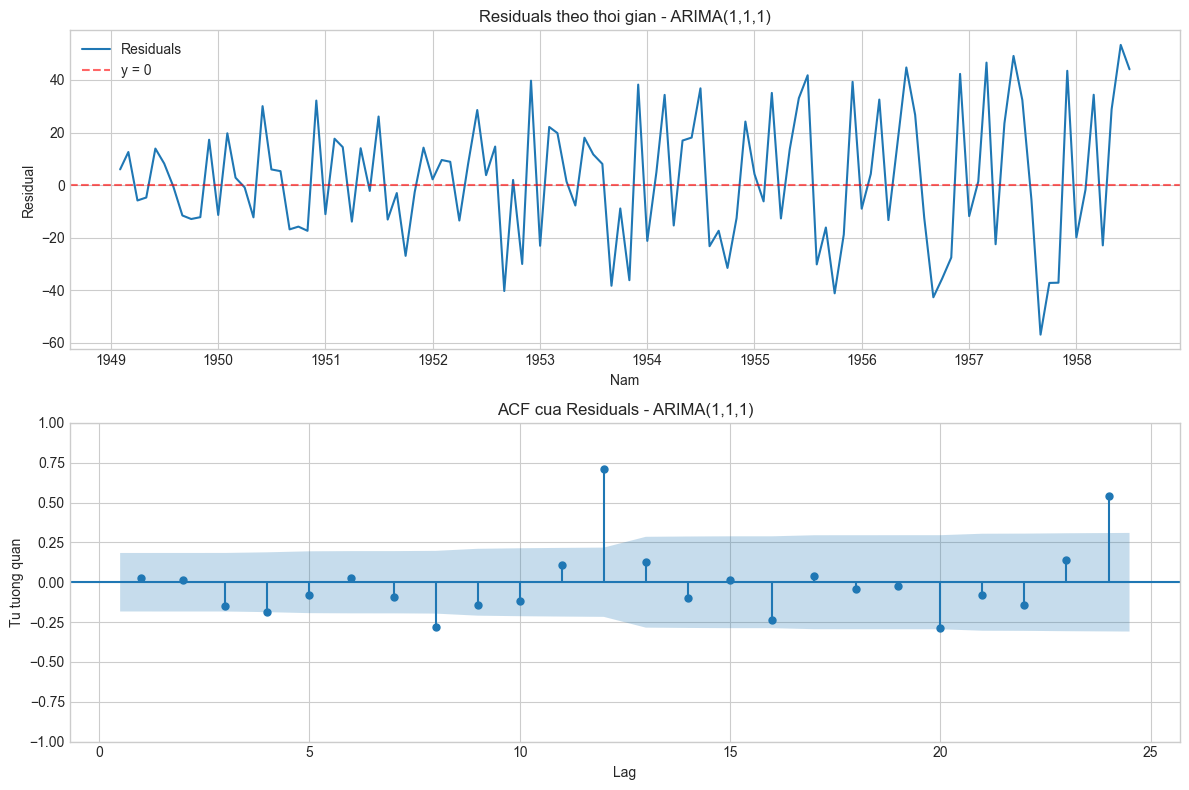

Mean residual : 2.688  (Std = 24.321)
Ljung-Box (lag=24) p-value : 0.0000
=> Con tu tuong quan (khong phai white noise).


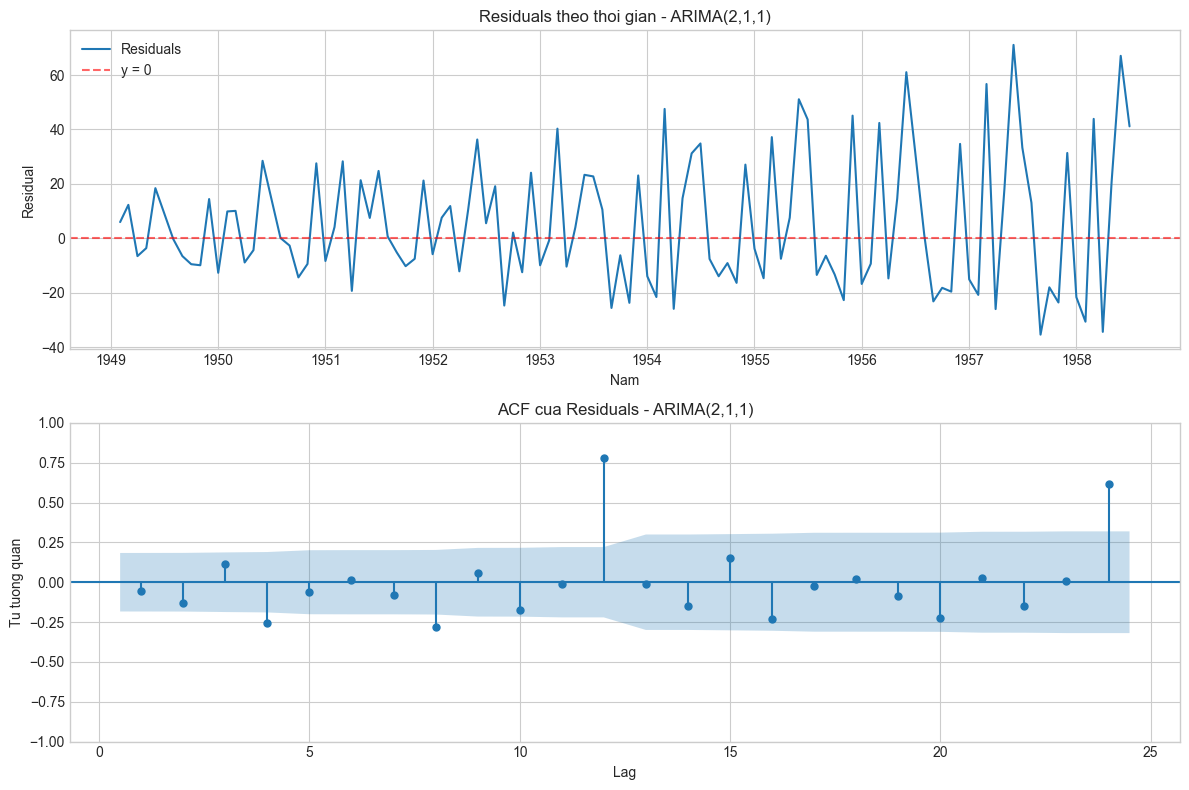

Mean residual : 5.568  (Std = 23.664)
Ljung-Box (lag=24) p-value : 0.0000
=> Con tu tuong quan (khong phai white noise).


In [17]:
diag = {}
for name, order in orders.items():
    tag = name.replace('(', '').replace(')', '').replace(',', '').lower()
    diag[name] = residual_diagnostics(models[name], order, lags=24, title=name,
                                      save_path=str(fig_dir / f'ARIMA_residuals_Dataset2{tag}.png'))

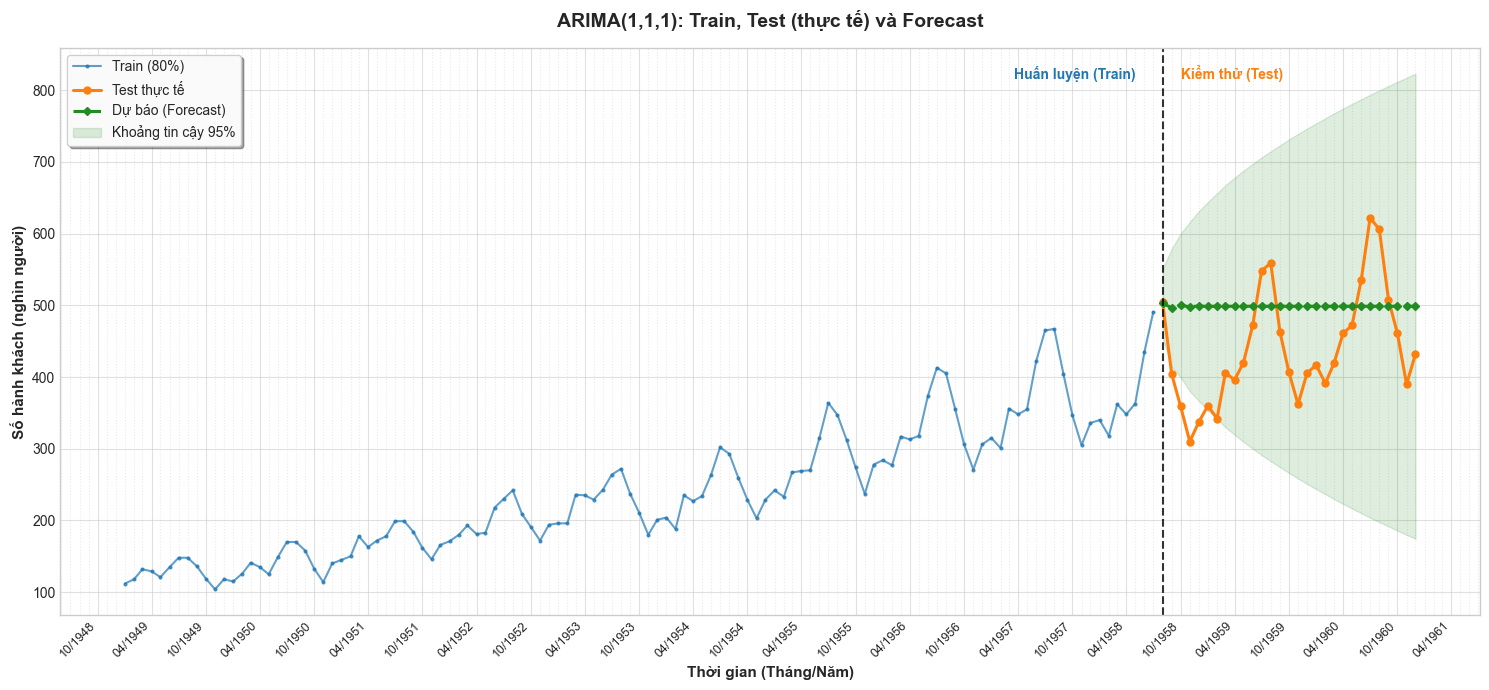

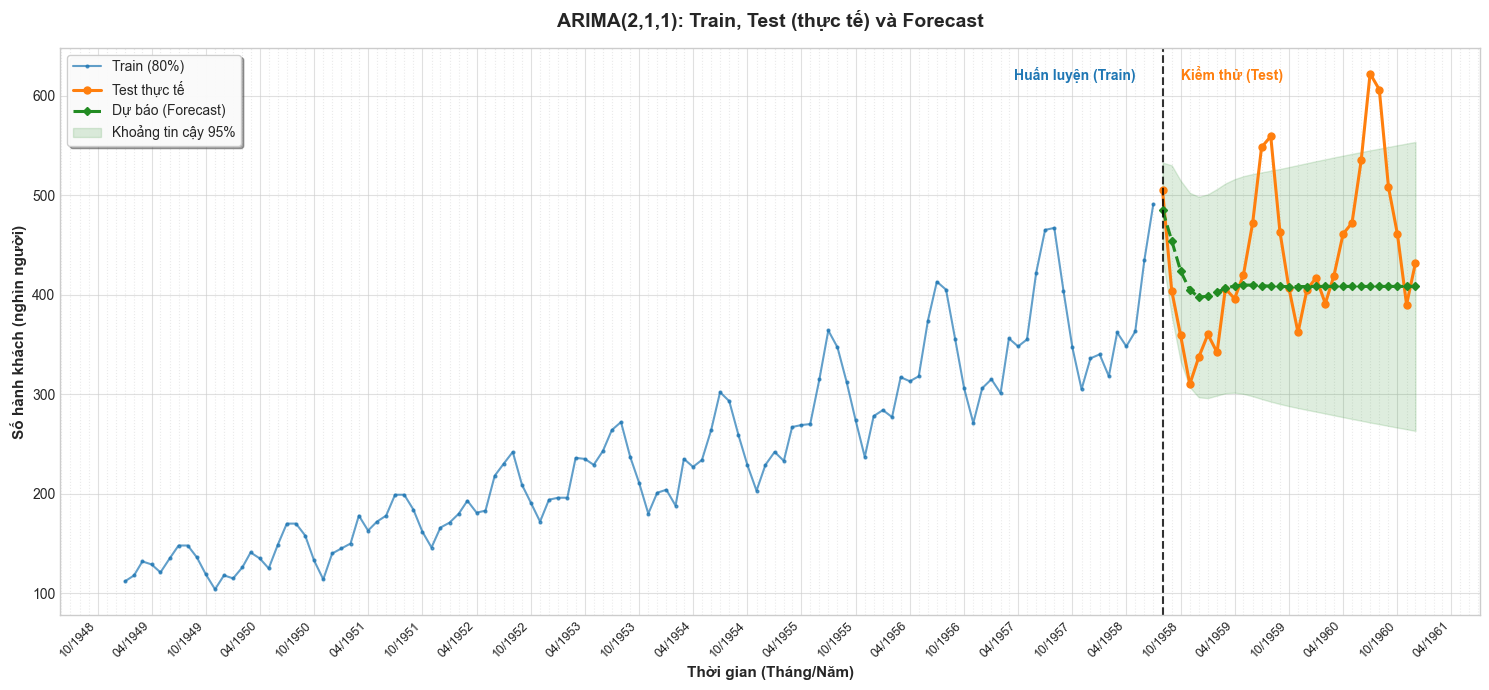

In [18]:
forecasts, conf_ints = {}, {}
for name in orders:
    forecasts[name], conf_ints[name] = forecast_test(models[name], steps=len(test))
    tag = name.replace('(', '').replace(')', '').replace(',', '').lower()
    plot_forecast(train, test, forecasts[name], conf_ints[name],
                  title=f'{name}: Train, Test (thực tế) và Forecast',
                  save_path=str(fig_dir / f'ARIMA_Train_Test_Forecast_Dataset2{tag}.png'))

In [19]:
results = pd.DataFrame({name: evaluate_forecast(test, forecasts[name]) for name in orders}).T
display(results.round(2))

# Các tháng sai lệch lớn nhất 
for name in orders:
    err = (test - forecasts[name])
    top = pd.DataFrame({'Thực tế': test, 'Dự báo': forecasts[name].round(1), 'Sai lệch': err.round(1)})
    print(f"\n3 tháng sai lệch lớn nhất - {name}:")
    display(top.loc[err.abs().nlargest(3).index])

print(f"\nTrung bình Test = {test.mean():.1f}; độ lệch chuẩn Test = {test.std():.1f}")

,MAE,RMSE,MAPE (%),R2
"ARIMA(1,1,1)",85.25,97.50,21.29,-0.56
"ARIMA(2,1,1)",60.53,82.62,12.90,-0.12



3 tháng sai lệch lớn nhất - ARIMA(1,1,1):


,Thực tế,Dự báo,Sai lệch
Month,,,
1958-11-01,310,498.2,-188.2
1958-12-01,337,499.0,-162.0
1959-02-01,342,498.8,-156.8



3 tháng sai lệch lớn nhất - ARIMA(2,1,1):


,Thực tế,Dự báo,Sai lệch
Month,,,
1960-07-01,622,408.3,213.7
1960-08-01,606,408.3,197.7
1959-08-01,559,408.5,150.5



Trung bình Test = 440.3; độ lệch chuẩn Test = 79.5


## Trả lời các câu hỏi của Bài 5

**1. Vì sao không được shuffle dữ liệu chuỗi thời gian? Test set dùng để làm gì?**

Các quan sát chuỗi thời gian phụ thuộc vào quá khứ của chúng. Nếu xáo trộn, mô hình sẽ được học từ các tháng nằm *sau* tháng cần dự báo (rò rỉ dữ liệu từ tương lai) và cấu trúc tự tương quan bị phá vỡ. Tập Test là phần dữ liệu mô hình chưa từng thấy, chỉ dùng ở bước cuối để đo khả năng dự báo thực sự trên tương lai.

**2. Ý nghĩa của p, d, q đã chọn?**

- **p** (AR) AutoRegressive: số giá trị quá khứ của chính chuỗi được dùng để dự báo (p = 1 hoặc 2).
- **d** (I) Integrated: số lần sai phân để loại xu hướng (d = 1). Lưu ý ở Bài 3, ADF sau sai phân bậc 1 vẫn cho p-value = 0.106 (chưa dừng ở mức 5%) vì còn mùa vụ; chuỗi chỉ dừng khi có thêm sai phân mùa vụ (D = 1, s = 12).
- **q** (MA) Moving Average: số sai số dự báo quá khứ được dùng để hiệu chỉnh (q = 1).

**3. Mô hình có hội tụ không?**

Có. Cả hai mô hình hội tụ (`warnflag = 0`, 15 và 17 vòng lặp), không có cảnh báo hội tụ.

**4. Residuals có phải white noise không?**

Không. Mean gần 0 nhưng ACF của phần dư vượt ngưỡng tin cậy ở nhiều lag (mạnh nhất là lag 12 và 24) và Ljung-Box có p-value ≈ 0 (1.4e-22 và 3.5e-27).

**5. Nếu residuals còn tự tương quan thì điều chỉnh gì?**

Tự tương quan tập trung ở lag 12, 24 nên vấn đề là **mùa vụ**, không phải do thiếu p hoặc q ở lag ngắn. Hướng điều chỉnh: thêm thành phần mùa vụ, tức SARIMA(p,d,q)(P,D,Q)₁₂ với D = 1 (Bài nâng cao). Có thể cân nhắc thêm biến đổi log để ổn định phương sai vì biên độ mùa vụ tăng dần.

**6. Dự đoán có bám sát xu hướng không?**

Không. ARIMA(1,1,1) dự báo gần như phẳng quanh 500, ARIMA(2,1,1) giảm dần và dao động tắt dần quanh khoảng 408, trong khi thực tế vừa tăng vừa có chu kỳ mùa vụ rõ.

**7. Sai lệch lớn nhất xảy ra ở đâu?**

ARIMA(1,1,1): tháng 11/1958 (thực tế 310, dự báo 498, lệch 188). ARIMA(2,1,1): tháng 07/1960 (thực tế 622, dự báo 408, lệch 214). Sai lệch lớn tập trung ở các đỉnh mùa hè và đáy mùa đông vì mô hình không có thành phần mùa vụ.

**8. Chỉ số nào nhạy với outlier nhất?**

**RMSE**, vì bình phương sai số nên các điểm sai lớn được nhân trọng số mạnh. Ở ARIMA(2,1,1), tỉ lệ RMSE/MAE = 1.36 (cao hơn mức 1.14 của ARIMA(1,1,1)) cho thấy sai số tập trung vào một số điểm lớn. MAPE thì nhạy với các điểm có giá trị thực tế nhỏ.

**9. RMSE lớn hay nhỏ nói lên điều gì?**

RMSE = 97.5 và 82.6 (nghìn hành khách) tương ứng khoảng 22% và 19% mức trung bình của Test (440), nên sai số **lớn**. Đáng chú ý, RMSE xấp xỉ độ lệch chuẩn của chính tập Test (79.5) và R² âm (−0.56 và −0.12), tức dự báo chưa tốt hơn việc đoán một hằng số bằng trung bình Test. Nguyên nhân chính là mô hình chưa có thành phần mùa vụ.

### Bài 6: Bài Tập Nâng Cao (SARIMA)

**Mục tiêu:** Triển khai mô hình SARIMA để giải quyết triệt để tính mùa vụ mà ARIMA không làm được.

**Thực thi:** Xác định tham số mùa vụ từ đồ thị bài 4: 

- **Nhóm mô hình SARIMA (p,d,q)(P,D,Q)s**

   ($p \in \{0, 1\}$, $q \in \{0, 1, 3\}$ và $Q \in \{0, 1\}$)

 ***Nhóm ưu tiên (P=0, Q=0):***
SARIMA(1,1,1)(0,1,0)$_{12}$, 
SARIMA(1,1,0)(0,1,0)$_{12}$, 
SARIMA(0,1,1)(0,1,0)$_{12}$

 ***Nhóm dự phòng dư mùa vụ (Q=1):***
SARIMA(0,1,3)(0,1,0)$_{12}$, 
SARIMA(1,1,3)(0,1,0)$_{12}$, 
SARIMA(1,1,3)(0,1,1)$_{12}$ 

 ***Nhóm mở rộng bắt nhiễu ngắn hạn (q=3):***
SARIMA(1,1,1)(0,1,1)$_{12}$
SARIMA(1,1,0)(0,1,1)$_{12}$, 
SARIMA(0,1,1)(0,1,1)$_{12}$

Dự báo và lập bảng so sánh đối đầu với ARIMA.


In [20]:
import sys
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split

# 1. Định vị thư mục gốc dự án để nạp các module từ src/
project_root = Path(os.getcwd())
while project_root.name != '' and not (project_root / 'src').exists():
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from src.data_loader import load_and_prep_data
from src.lab02_utils.modeling import (
    fit_arima,
    fit_sarima,
    residual_diagnostics,
    forecast_test,
    evaluate_forecast,
    plot_forecast
)

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

fig_dir = project_root / 'reports' / 'figures' / 'lab02'
fig_dir.mkdir(parents=True, exist_ok=True)

# 4. ĐỊNH NGHĨA HỆ MÀU QUY CHUẨN ĐỒNG NHẤT XUYÊN SUỐT BÀI
COLORS = {
    'train': 'tab:blue',        
    'test': 'tab:orange',      
    'arima111': 'tab:gray',     
    'arima211': 'tab:red',      
    'sarima_best': 'tab:green', 
    'sarima_cand2': 'tab:purple',
    'sarima_cand3': 'tab:brown', 
    'ref_line': 'red'         
}



In [21]:
processed_dir = project_root / 'data' / 'processed' / 'lab02'
train_file = processed_dir / 'train_data.csv'
test_file = processed_dir / 'test_data.csv'

if train_file.exists() and test_file.exists():
    train_df = pd.read_csv(train_file, parse_dates=['Month'], index_col='Month')
    test_df = pd.read_csv(test_file, parse_dates=['Month'], index_col='Month')
else:
    df = load_and_prep_data(str(project_root / 'data' / 'raw' / 'AirPassengers.csv'), date_col='Month')
    train_df, test_df = train_test_split(df, test_size=0.2, shuffle=False)
    processed_dir.mkdir(parents=True, exist_ok=True)
    train_df.to_csv(train_file)
    test_df.to_csv(test_file)

# Gán tần suất bắt đầu tháng ('MS') cho chuỗi thời gian
train = train_df['Passengers'].asfreq('MS')
test = test_df['Passengers'].asfreq('MS')

print(f"Train: {len(train)} quan sát ({train.index.min():%m/%Y} - {train.index.max():%m/%Y})")
print(f"Test : {len(test)} quan sát ({test.index.min():%m/%Y} - {test.index.max():%m/%Y})")

Train: 115 quan sát (01/1949 - 07/1958)
Test : 29 quan sát (08/1958 - 12/1960)


In [22]:
sarima_candidates = {
    'SARIMA(1,1,1)x(0,1,0)12': {'order': (1, 1, 1), 'seasonal_order': (0, 1, 0, 12)},
    'SARIMA(1,1,0)x(0,1,0)12': {'order': (1, 1, 0), 'seasonal_order': (0, 1, 0, 12)},
    'SARIMA(0,1,1)x(0,1,0)12': {'order': (0, 1, 1), 'seasonal_order': (0, 1, 0, 12)},
    
    'SARIMA(0,1,3)x(0,1,0)12': {'order': (0, 1, 3), 'seasonal_order': (0, 1, 0, 12)},
    'SARIMA(1,1,3)x(0,1,0)12': {'order': (1, 1, 3), 'seasonal_order': (0, 1, 0, 12)},
    'SARIMA(1,1,3)x(0,1,1)12': {'order': (1, 1, 3), 'seasonal_order': (0, 1, 1, 12)},
    
    'SARIMA(1,1,1)x(0,1,1)12': {'order': (1, 1, 1), 'seasonal_order': (0, 1, 1, 12)},
    'SARIMA(1,1,0)x(0,1,1)12': {'order': (1, 1, 0), 'seasonal_order': (0, 1, 1, 12)},
    'SARIMA(0,1,1)x(0,1,1)12': {'order': (0, 1, 1), 'seasonal_order': (0, 1, 1, 12)},
}

fitted_sarima = {}
for name, cfg in sarima_candidates.items():
    print(f"\n--- Huấn luyện {name} ---")
    fitted_sarima[name] = fit_sarima(train, order=cfg['order'], seasonal_order=cfg['seasonal_order'])

# Bảng so sánh tiêu chuẩn thông tin AIC và BIC trên tập Train
sarima_aic_bic = pd.DataFrame({
    name: {'AIC': m.aic, 'BIC': m.bic}
    for name, m in fitted_sarima.items()
}).T
print("\n===== BẢNG SO SÁNH AIC & BIC CỦA CÁC MÔ HÌNH SARIMA =====")
display(sarima_aic_bic.round(2))


--- Huấn luyện SARIMA(1,1,1)x(0,1,0)12 ---
===== SARIMA(1, 1, 1)x(0, 1, 0, 12) =====
AIC : 742.94
BIC : 750.75

--- Huấn luyện SARIMA(1,1,0)x(0,1,0)12 ---
===== SARIMA(1, 1, 0)x(0, 1, 0, 12) =====
AIC : 748.83
BIC : 754.06

--- Huấn luyện SARIMA(0,1,1)x(0,1,0)12 ---
===== SARIMA(0, 1, 1)x(0, 1, 0, 12) =====
AIC : 742.92
BIC : 748.13

--- Huấn luyện SARIMA(0,1,3)x(0,1,0)12 ---
===== SARIMA(0, 1, 3)x(0, 1, 0, 12) =====
AIC : 726.91
BIC : 737.25

--- Huấn luyện SARIMA(1,1,3)x(0,1,0)12 ---
===== SARIMA(1, 1, 3)x(0, 1, 0, 12) =====
AIC : 728.13
BIC : 741.05

--- Huấn luyện SARIMA(1,1,3)x(0,1,1)12 ---
===== SARIMA(1, 1, 3)x(0, 1, 1, 12) =====
AIC : 639.62
BIC : 654.35

--- Huấn luyện SARIMA(1,1,1)x(0,1,1)12 ---
===== SARIMA(1, 1, 1)x(0, 1, 1, 12) =====
AIC : 659.33
BIC : 669.24

--- Huấn luyện SARIMA(1,1,0)x(0,1,1)12 ---
===== SARIMA(1, 1, 0)x(0, 1, 1, 12) =====
AIC : 666.75
BIC : 674.21

--- Huấn luyện SARIMA(0,1,1)x(0,1,1)12 ---
===== SARIMA(0, 1, 1)x(0, 1, 1, 12) =====
AIC : 659.34
BIC :

,AIC,BIC
"SARIMA(1,1,1)x(0,1,0)12",742.94,750.75
"SARIMA(1,1,0)x(0,1,0)12",748.83,754.06
"SARIMA(0,1,1)x(0,1,0)12",742.92,748.13
"SARIMA(0,1,3)x(0,1,0)12",726.91,737.25
"SARIMA(1,1,3)x(0,1,0)12",728.13,741.05
"SARIMA(1,1,3)x(0,1,1)12",639.62,654.35
"SARIMA(1,1,1)x(0,1,1)12",659.33,669.24
"SARIMA(1,1,0)x(0,1,1)12",666.75,674.21
"SARIMA(0,1,1)x(0,1,1)12",659.34,666.77


**Kết luận từ kết quả đo lường AIC/BIC (Tập Train):**

- **Sự vượt trội của thành phần MA mùa vụ ($Q=1$):** 
Nhìn vào bảng kết quả, có sự phân hóa rõ rệt giữa hai nhóm mô hình. 
Toàn bộ các cấu hình chứa tham số $Q=1$ đều có chỉ số AIC/BIC thấp vượt trội (dao động từ 639 đến 666), áp đảo hoàn toàn nhóm $Q=0$ (dao động từ 726 đến 748). 
Khoảng cách lên tới gần 100 điểm AIC khẳng định giả thuyết ban đầu là chính xác: việc bổ sung $Q=1$ là bắt buộc để hấp thụ triệt để phần dư mùa vụ và xử lý hiện tượng quá sai phân.

- **Lựa chọn Top 4 mô hình ứng viên:** 
Dựa trên nguyên tắc ưu tiên các giá trị AIC và BIC nhỏ nhất, 4 mô hình sau đây tách biệt hoàn toàn so với phần còn lại và sẽ được chọn làm nhóm ứng viên chung kết:

    ***SARIMA(1,1,3)(0,1,1)$_{12}$:*** (Top 1) Đạt hiệu suất khớp dữ liệu tốt nhất tuyệt đối với AIC = 639.62 và BIC = 654.35.

    ***SARIMA(1,1,1)(0,1,1)$_{12}$:*** (Top 2) AIC = 659.33.

    ***SARIMA(0,1,1)(0,1,1)$_{12}$:*** (Top 3) Mặc dù AIC (659.34) xấp xỉ Top 2, nhưng mô hình này ưu việt hơn về mặt tiết kiệm tham số, thể hiện qua chỉ số BIC ***thấp hơn (666.77 so với 669.24).
 
    ***SARIMA(1,1,0)(0,1,1)$_{12}$:*** (Top 4) AIC = 666.75.

===== KIỂM ĐỊNH PHẦN DƯ (LJUNG-BOX) CHO TOP 4 MÔ HÌNH =====

--- Đang phân tích: SARIMA(1,1,3)x(0,1,1)12 ---


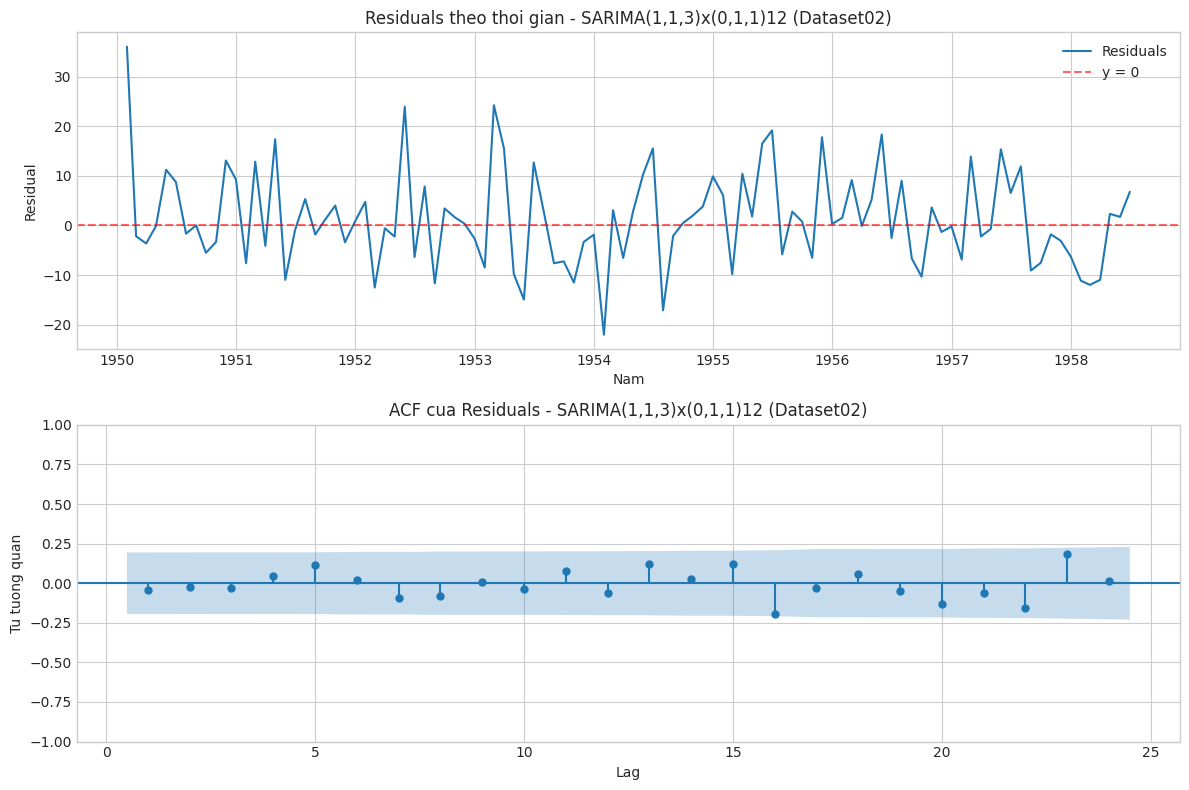

Mean residual : 1.347  (Std = 9.750)
Ljung-Box (lag=24) p-value : 0.4105
=> Chua thay tu tuong quan o lag kiem tra.

--- Đang phân tích: SARIMA(1,1,1)x(0,1,1)12 ---


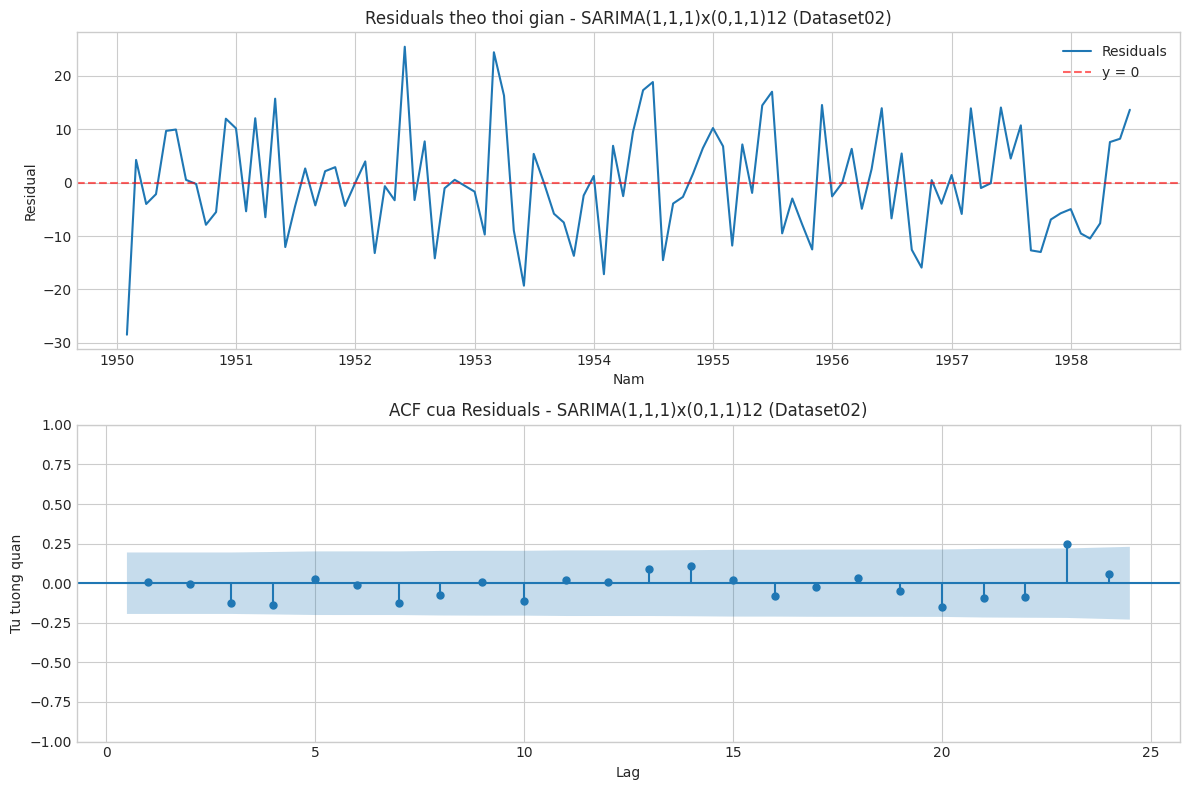

Mean residual : -0.006  (Std = 9.950)
Ljung-Box (lag=24) p-value : 0.3909
=> Chua thay tu tuong quan o lag kiem tra.

--- Đang phân tích: SARIMA(0,1,1)x(0,1,1)12 ---


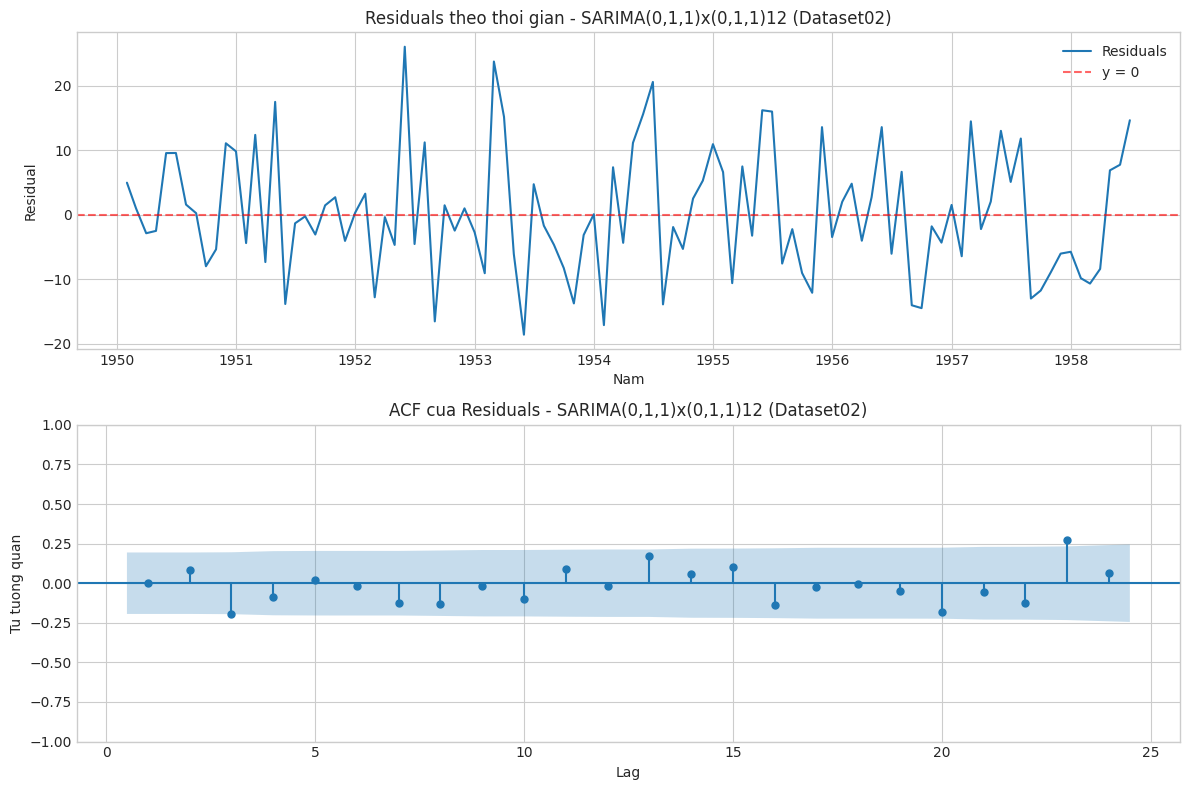

Mean residual : 0.307  (Std = 9.616)
Ljung-Box (lag=24) p-value : 0.0468
=> Con tu tuong quan (khong phai white noise).

--- Đang phân tích: SARIMA(1,1,0)x(0,1,1)12 ---


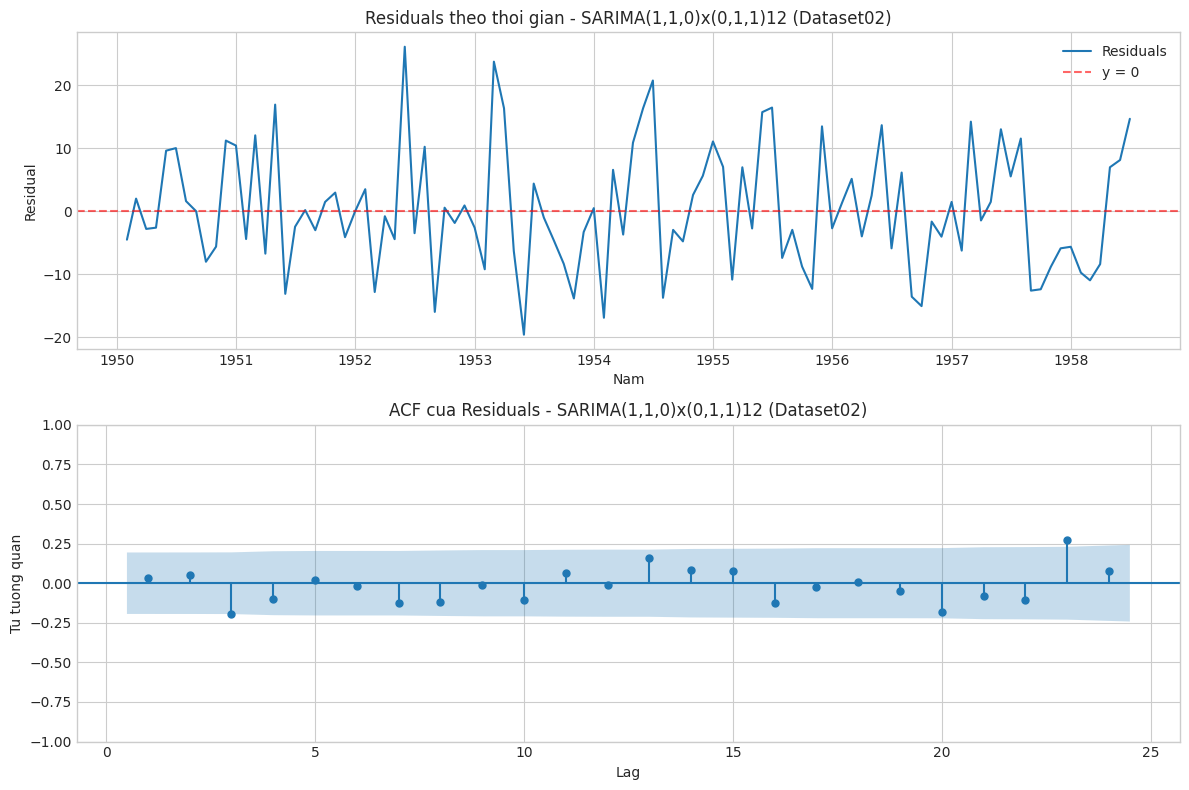

Mean residual : 0.220  (Std = 9.601)
Ljung-Box (lag=24) p-value : 0.0710
=> Chua thay tu tuong quan o lag kiem tra.
             SARIMA(1,1,3)x(0,1,1)12  SARIMA(1,1,1)x(0,1,1)12  \
mean                        1.347138                -0.006360   
std                         9.750369                 9.949551   
ljung_box_p                 0.410523                 0.390881   

             SARIMA(0,1,1)x(0,1,1)12  SARIMA(1,1,0)x(0,1,1)12  
mean                        0.307291                 0.220342  
std                         9.616044                 9.601132  
ljung_box_p                 0.046830                 0.070958  


In [23]:
# (Hàm residual_diagnostics cần tham số order để tính bậc tự do cho kiểm định Ljung-Box)
top_4_models = {
    'SARIMA(1,1,3)x(0,1,1)12': (1, 1, 3), # Top 1
    'SARIMA(1,1,1)x(0,1,1)12': (1, 1, 1), # Top 2
    'SARIMA(0,1,1)x(0,1,1)12': (0, 1, 1), # Top 3
    'SARIMA(1,1,0)x(0,1,1)12': (1, 1, 0)  # Top 4
}

diag_results = {}

print("===== KIỂM ĐỊNH PHẦN DƯ (LJUNG-BOX) CHO TOP 4 MÔ HÌNH =====")

for model_name, order_tuple in top_4_models.items():
    print(f"\n--- Đang phân tích: {model_name} ---")
    model = fitted_sarima[model_name]
    
    # Tạo tên file ảnh tự động, an toàn cho hệ điều hành (chuyển dấu ngoặc/phẩy thành dấu gạch dưới)
    # Ví dụ: SARIMA(1,1,3)x(0,1,1)12 -> SARIMA_1_1_3_x_0_1_1_12_residuals.png
    safe_name = model_name.replace('(', '_').replace(')', '_').replace(',', '_')
    save_file_path = str(fig_dir / f"{safe_name}_residuals.png")
    
    # Chạy hàm chẩn đoán
    diag_summary = residual_diagnostics(
        model,
        order=order_tuple,
        lags=24,
        title=f"{model_name} (Dataset02)",
        save_path=save_file_path,
        n_skip=13
    )
    
    # Lưu lại kết quả
    diag_results[model_name] = diag_summary


# Hiển thị tóm tắt nếu hàm trả về DataFrame/Dict
print(pd.DataFrame(diag_results))

### Đánh giá kiểm định phần dư (Ljung-Box Test tại lag = 24)

Sau khi chọn lọc top 4 mô hình có chỉ số AIC/BIC thấp nhất, kiểm định Ljung-Box được áp dụng để kiểm tra tính nhiễu trắng (White Noise) của phần dư. Kết quả thu được như sau:

*   Mô hình **SARIMA(0,1,1)x(0,1,1)12** có p-value = 0.0468 (< 0.05), chứng tỏ phần dư vẫn còn tự tương quan, mô hình chưa trích xuất hết quy luật dữ liệu. -> **Loại bỏ**.
*   Mô hình **SARIMA(1,1,0)x(0,1,1)12** có p-value = 0.0710, vượt qua kiểm định nhưng ở mức ranh giới rất thấp do mô hình còn bỏ sót nhiễu tại các độ trễ ngắn hạn.(trên đồ thị ACF mô hình này có tới 2 gai chạm ngưỡng ở lag 3 và lag 23).

*   Mô hình **SARIMA(1,1,1)x(0,1,1)12** có p-value = 0.3909 (> 0.05), Mặc dù có gai ở lag 23, nhưng tổng thể 24 lags vẫn đủ ngẫu nhiên để vượt qua kiểm định.

*   Mô hình **SARIMA(1,1,3)x(0,1,1)12** đạt p-value cao nhất (0.4105), hoàn toàn triệt tiêu được tự tương quan trong phần dư. Điều này đồng nhất với biểu đồ ACF khi các giá trị độ trễ đều nằm gọn trong dải tin cậy.

**Kết luận chung cuộc:** 
Kết hợp cả 3 yếu tố: (1) Chỉ số AIC/BIC thấp nhất, (2) Đồ thị ACF sạch nhất, và (3) P-value Ljung-Box cao nhất, mô hình **SARIMA(1,1,3)(0,1,1)12** chính thức được chọn làm mô hình tiêu biểu (Best Model) để tiến hành dự báo trên tập Test.

In [24]:
#Trích xuất 3 mô hình Sarima tốt nhất 
top_3_names = [
    'SARIMA(1,1,3)x(0,1,1)12', 
    'SARIMA(1,1,1)x(0,1,1)12', 
    'SARIMA(1,1,0)x(0,1,1)12'
]

sarima_forecasts = {}
sarima_conf_ints = {}

# Chạy dự báo cho từng mô hình
for name in top_3_names:
    model = fitted_sarima[name]
    pred, conf = forecast_test(model, steps=len(test))
    pred.index = test.index
    conf.index = test.index
    sarima_forecasts[name] = pred
    sarima_conf_ints[name] = conf

===== VẼ ĐỒ THỊ DỰ BÁO CHO TOP 3 MÔ HÌNH =====
Đang vẽ và lưu đồ thị cho: SARIMA(1,1,3)x(0,1,1)12 ...


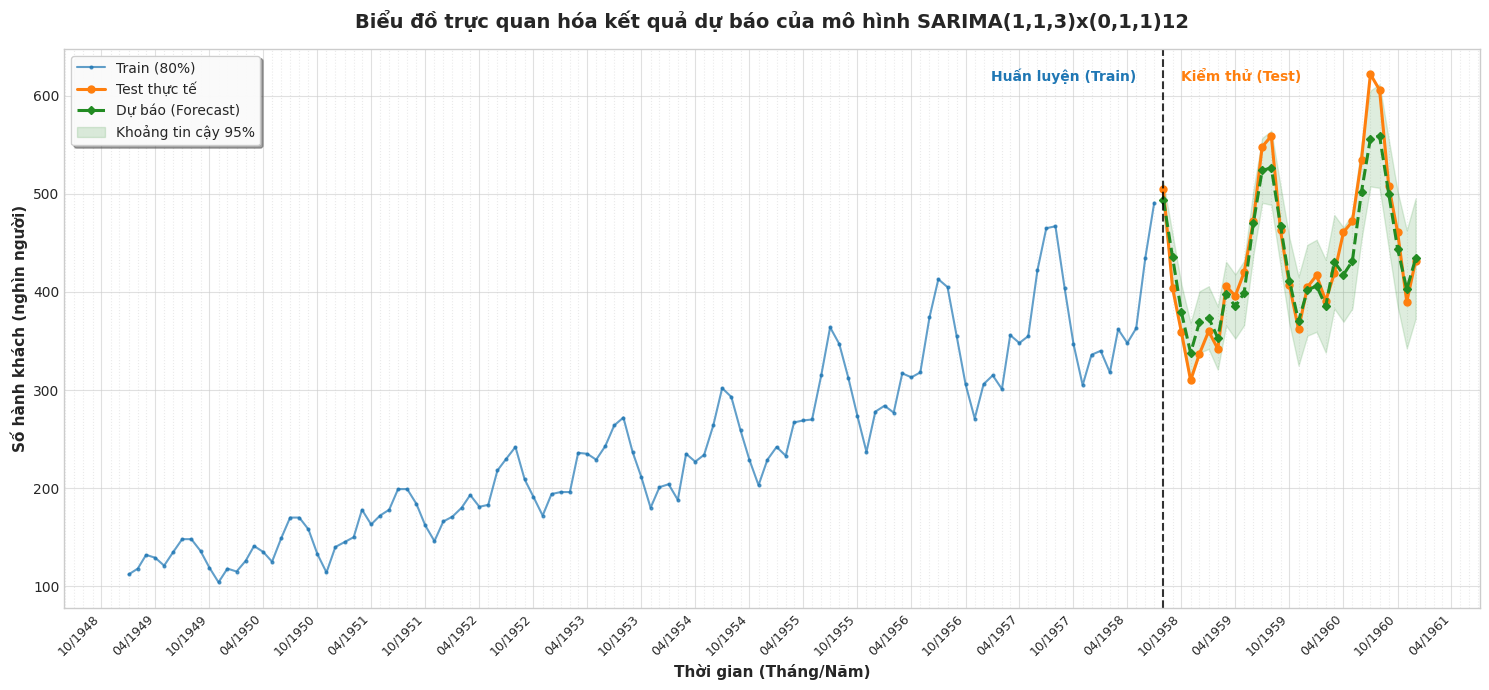

Đang vẽ và lưu đồ thị cho: SARIMA(1,1,1)x(0,1,1)12 ...


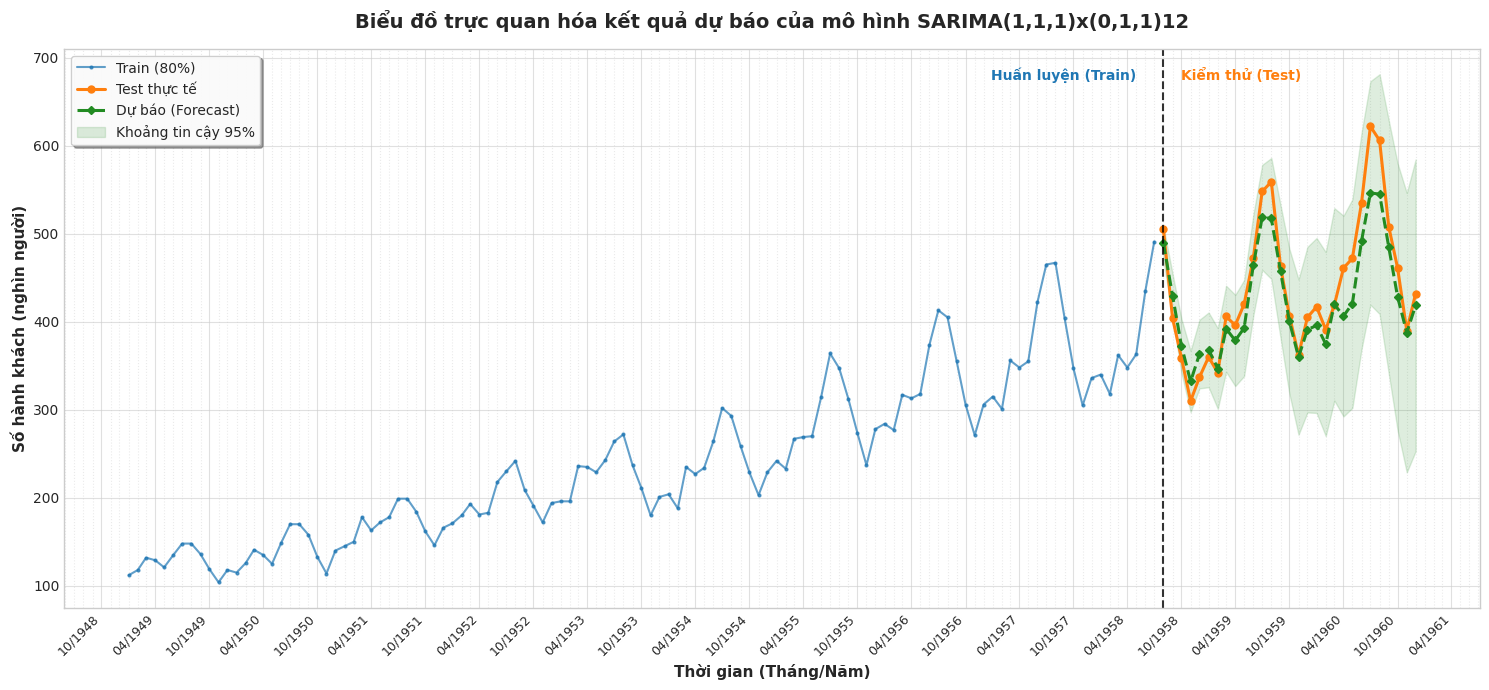

Đang vẽ và lưu đồ thị cho: SARIMA(1,1,0)x(0,1,1)12 ...


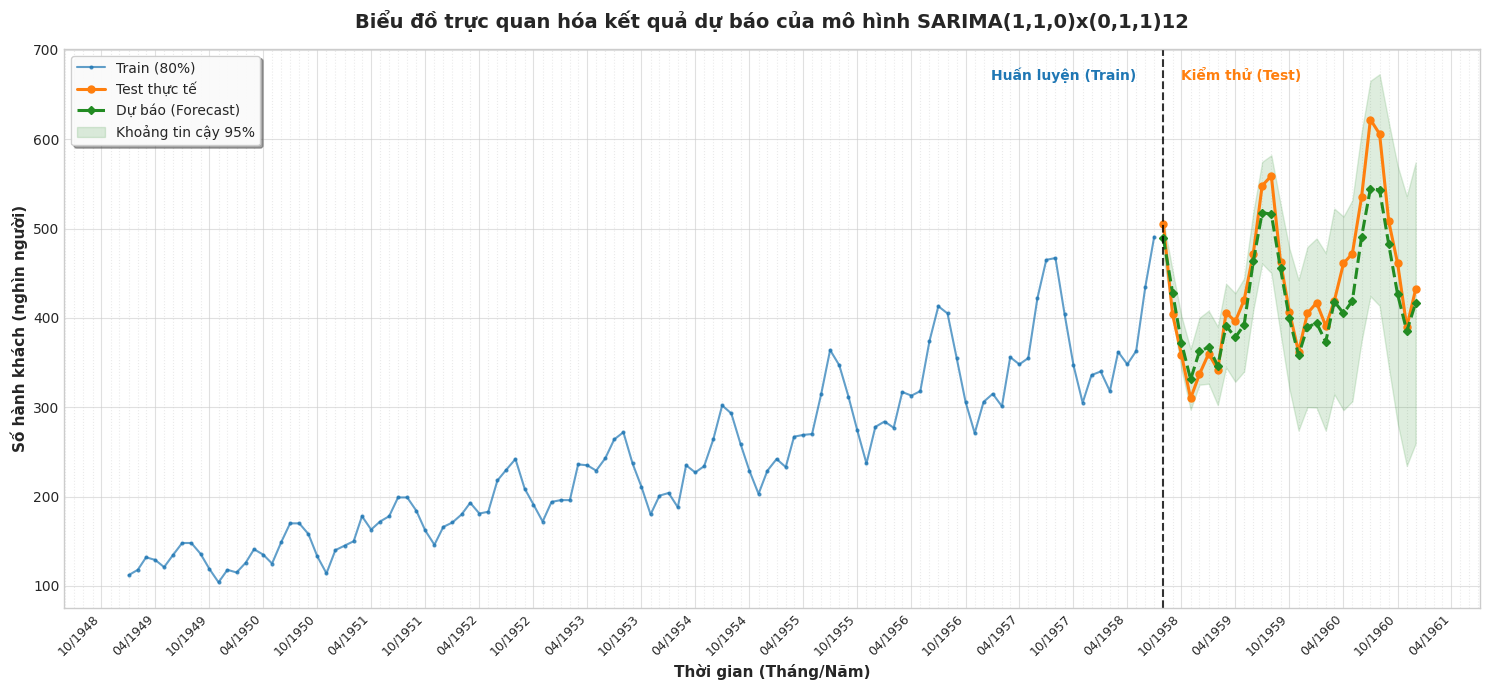


Hoàn tất! Các đồ thị đã được lưu vào thư mục: d:\vscode\Lab_TimeSeries\reports\figures\lab02


In [25]:
print("===== VẼ ĐỒ THỊ DỰ BÁO CHO TOP 3 MÔ HÌNH =====")

# Lặp qua danh sách 3 mô hình tốt nhất
for name in top_3_names:
    # Lấy dữ liệu dự báo và khoảng tin cậy tương ứng với mô hình
    fc_mean = sarima_forecasts[name]
    conf_int = sarima_conf_ints[name]
    
    # Tạo tên file an toàn (đổi dấu ngoặc, phẩy thành gạch dưới)
    safe_name = name.replace('(', '_').replace(')', '_').replace(',', '_')
    save_file_path = str(fig_dir / f"{safe_name}_forecast.png")
    
    print(f"Đang vẽ và lưu đồ thị cho: {name} ...")
    
    # Gọi hàm plot_forecast
    plot_forecast(
        train,
        test,
        fc_mean,
        conf_int=conf_int,
        title=f"Biểu đồ trực quan hóa kết quả dự báo của mô hình {name}",
        
        save_path=save_file_path
    )
    
print("\nHoàn tất! Các đồ thị đã được lưu vào thư mục:", fig_dir)

In [26]:
# Đánh giá tổng quan (RMSE, MAPE...)
sarima_metrics_df = pd.DataFrame({
    name: evaluate_forecast(test, sarima_forecasts[name])
    for name in top_3_names
}).T

print("===== ĐÁNH GIÁ HIỆU NĂNG 3 MÔ HÌNH TRÊN TẬP TEST =====")
display(sarima_metrics_df.round(2))

===== ĐÁNH GIÁ HIỆU NĂNG 3 MÔ HÌNH TRÊN TẬP TEST =====


,MAE,RMSE,MAPE (%),R2
"SARIMA(1,1,3)x(0,1,1)12",19.43,24.85,4.31,0.90
"SARIMA(1,1,1)x(0,1,1)12",23.37,29.92,5.01,0.85
"SARIMA(1,1,0)x(0,1,1)12",24.25,30.77,5.19,0.84


In [27]:
# Phân tích Top 3 tháng có sai số tuyệt đối lớn nhất cho TỪNG MÔ HÌNH
print("\n===== PHÂN TÍCH SAI SỐ ĐỘT BIẾN =====")
for name in top_3_names:
    fc = sarima_forecasts[name]
    error_df = pd.DataFrame({
        'Thực tế': test,
        'Dự báo': fc.round(1),
        'Sai số (TT - DB)': (test - fc).round(1),
        'Sai số tuyệt đối': np.abs(test - fc).round(1),
        'Sai số (%)': (np.abs(test - fc) / test * 100).round(2)
    })
    
    print(f"\nTop 3 tháng dự báo lệch nhất của {name}:")
    display(error_df.sort_values(by='Sai số tuyệt đối', ascending=False).head(3))


===== PHÂN TÍCH SAI SỐ ĐỘT BIẾN =====

Top 3 tháng dự báo lệch nhất của SARIMA(1,1,3)x(0,1,1)12:


,Thực tế,Dự báo,Sai số (TT - DB),Sai số tuyệt đối,Sai số (%)
Month,,,,,
1960-07-01,622,556.5,65.5,65.5,10.54
1960-08-01,606,559.0,47.0,47.0,7.75
1960-04-01,461,417.7,43.3,43.3,9.39



Top 3 tháng dự báo lệch nhất của SARIMA(1,1,1)x(0,1,1)12:


,Thực tế,Dự báo,Sai số (TT - DB),Sai số tuyệt đối,Sai số (%)
Month,,,,,
1960-07-01,622,546.3,75.7,75.7,12.17
1960-08-01,606,545.0,61.0,61.0,10.06
1960-04-01,461,406.5,54.5,54.5,11.83



Top 3 tháng dự báo lệch nhất của SARIMA(1,1,0)x(0,1,1)12:


,Thực tế,Dự báo,Sai số (TT - DB),Sai số tuyệt đối,Sai số (%)
Month,,,,,
1960-07-01,622,544.8,77.2,77.2,12.41
1960-08-01,606,543.2,62.8,62.8,10.36
1960-04-01,461,405.1,55.9,55.9,12.12


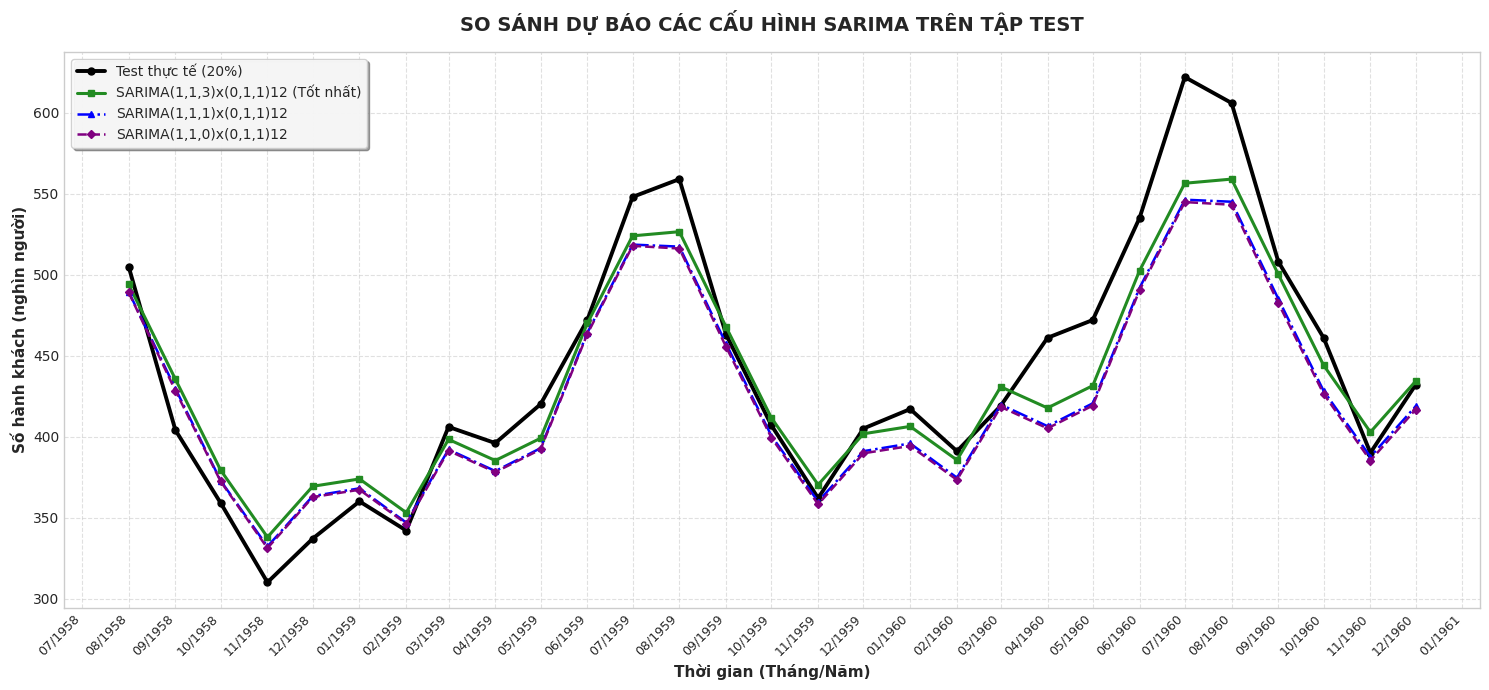

In [28]:
# Vẽ đồ thị so sánh các mô hình SARIMA với Test thực tế 
plt.figure(figsize=(15, 7))

# 1. Vẽ đường Test thực tế 
plt.plot(test.index, test.values, color='black', linewidth=2.8, 
         marker='o', markersize=5, label="Test thực tế (20%)")

# 2. Vẽ đường dự báo của Top 1 
plt.plot(test.index, sarima_forecasts['SARIMA(1,1,3)x(0,1,1)12'], color='forestgreen', linewidth=2.2, 
         linestyle='-', marker='s', markersize=4, label="SARIMA(1,1,3)x(0,1,1)12 (Tốt nhất)")

# 3. Vẽ đường dự báo của Top 2 
plt.plot(test.index, sarima_forecasts['SARIMA(1,1,1)x(0,1,1)12'], color='blue', linewidth=1.8, 
         linestyle='-.', marker='^', markersize=4, label="SARIMA(1,1,1)x(0,1,1)12")

# 4. Vẽ đường dự báo của Top 3 
plt.plot(test.index, sarima_forecasts['SARIMA(1,1,0)x(0,1,1)12'], color='purple', linewidth=1.8, 
         linestyle='--', marker='D', markersize=4, label="SARIMA(1,1,0)x(0,1,1)12")

# 5. TINH CHỈNH TRỤC X: Hiển thị chi tiết từng tháng
ax = plt.gca() # Lấy đối tượng trục hiện tại
# Đặt tick cho từng tháng
ax.xaxis.set_major_locator(mdates.MonthLocator())
# Định dạng nhãn tháng/năm (vd: 08/1958)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%Y'))
# Xoay nhãn 45 độ và căn lề phải để chữ không đâm vào trục
plt.xticks(rotation=45, ha='right', fontsize=9)

# 6. Tinh chỉnh thẩm mỹ tổng thể
plt.title("SO SÁNH DỰ BÁO CÁC CẤU HÌNH SARIMA TRÊN TẬP TEST", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Thời gian (Tháng/Năm)", fontsize=11, fontweight='bold')
plt.ylabel("Số hành khách (nghìn người)", fontsize=11, fontweight='bold')

# Thêm lưới nét đứt mờ để dễ gióng điểm
plt.grid(True, which='major', linestyle='--', alpha=0.6)
plt.legend(loc="upper left", frameon=True, facecolor='white', framealpha=0.9, shadow=True)

plt.tight_layout()

# Lưu và hiển thị 
plt.savefig(str(fig_dir / 'sarima_candidates_forecast_Dataset02.png'), dpi=150, bbox_inches='tight')
plt.show()

In [29]:
# LẬP BẢNG SO SÁNH ĐỐI ĐẦU TOÀN DIỆN: ARIMA VS SARIMA

# Khai báo mô hình SARIMA tốt nhất
best_sarima_name = 'SARIMA(1,1,3)x(0,1,1)12'
best_sarima_model = fitted_sarima[best_sarima_name]

comp_data = {
    'ARIMA(1,1,1)': {
        'AIC': round(models['ARIMA(1,1,1)'].aic, 2),
        'BIC': round(models['ARIMA(1,1,1)'].bic, 2),
        'MAE': round(results.loc['ARIMA(1,1,1)', 'MAE'], 2),
        'RMSE': round(results.loc['ARIMA(1,1,1)', 'RMSE'], 2),
        'MAPE (%)': round(results.loc['ARIMA(1,1,1)', 'MAPE (%)'], 2),
        'R2': round(results.loc['ARIMA(1,1,1)', 'R2'], 2),
        'Ljung-Box p-val': round(diag['ARIMA(1,1,1)']['ljung_box_p'], 4),
        'Trạng thái phần dư': 'Còn tự tương quan (Fail)',
        'Dạng đường dự báo': 'Tuyến tính, bỏ lỡ chu kỳ mùa vụ'
    },
    'ARIMA(2,1,1)': {
        'AIC': round(models['ARIMA(2,1,1)'].aic, 2),
        'BIC': round(models['ARIMA(2,1,1)'].bic, 2),
        'MAE': round(results.loc['ARIMA(2,1,1)', 'MAE'], 2),
        'RMSE': round(results.loc['ARIMA(2,1,1)', 'RMSE'], 2),
        'MAPE (%)': round(results.loc['ARIMA(2,1,1)', 'MAPE (%)'], 2),
        'R2': round(results.loc['ARIMA(2,1,1)', 'R2'], 2),
        'Ljung-Box p-val': round(diag['ARIMA(2,1,1)']['ljung_box_p'], 4),
        'Trạng thái phần dư': 'Còn tự tương quan (Fail)',
        'Dạng đường dự báo': 'Tuyến tính, bỏ lỡ chu kỳ mùa vụ'
    },
    best_sarima_name: {
        'AIC': round(best_sarima_model.aic, 2),
        'BIC': round(best_sarima_model.bic, 2),
        'MAE': round(sarima_metrics_df.loc[best_sarima_name, 'MAE'], 2),
        'RMSE': round(sarima_metrics_df.loc[best_sarima_name, 'RMSE'], 2),
        'MAPE (%)': round(sarima_metrics_df.loc[best_sarima_name, 'MAPE (%)'], 2),
        'R2': round(sarima_metrics_df.loc[best_sarima_name, 'R2'], 2),
        'Ljung-Box p-val': round(diag_results[best_sarima_name]['ljung_box_p'], 4), 
        'Trạng thái phần dư': 'Nhiễu trắng chuẩn (Pass)',
        'Dạng đường dự báo': 'Bám sát chính xác chu kỳ mùa vụ'
    }
}

comp_table = pd.DataFrame(comp_data).T
print("===== BẢNG SO SÁNH ĐỐI ĐẦU TRỰC DIỆN GIỮA ARIMA VÀ SARIMA =====")
display(comp_table)


===== BẢNG SO SÁNH ĐỐI ĐẦU TRỰC DIỆN GIỮA ARIMA VÀ SARIMA =====


,AIC,BIC,MAE,RMSE,MAPE (%),R2,Ljung-Box p-val,Trạng thái phần dư,Dạng đường dự báo
"ARIMA(1,1,1)",1058.25,1066.45,85.25,97.5,21.29,-0.56,0.0,Còn tự tương quan (Fail),"Tuyến tính, bỏ lỡ chu kỳ mùa vụ"
"ARIMA(2,1,1)",1058.65,1069.59,60.53,82.62,12.9,-0.12,0.0,Còn tự tương quan (Fail),"Tuyến tính, bỏ lỡ chu kỳ mùa vụ"
"SARIMA(1,1,3)x(0,1,1)12",639.62,654.35,19.43,24.85,4.31,0.9,0.4105,Nhiễu trắng chuẩn (Pass),Bám sát chính xác chu kỳ mùa vụ


Kết quả từ bảng đối chiếu trực diện chỉ ra sự áp đảo toàn diện của mô hình SARIMA so với các cấu hình ARIMA phi mùa vụ trên mọi phương diện đánh giá:

**1. Khả năng giải thích và Mức độ khớp dữ liệu (R² & AIC/BIC)**

- **Chỉ số R²:** Cả hai mô hình ARIMA đều ghi nhận $R^2$ âm (-0.56 và -0.12). Về mặt thống kê, điều này đồng nghĩa với việc dùng ARIMA để dự báo thậm chí còn tệ hơn việc lấy giá trị trung bình của tập Test. Ngược lại, SARIMA(1,1,3)x(0,1,1)12 đạt mức $R^2 = 0.90$, minh chứng mô hình đã giải thích thành công 90% sự biến thiên của lượng hành khách trong tương lai.

- **Tiêu chuẩn thông tin:** Việc bổ sung thành phần mùa vụ $(P, D, Q)_s$ giúp chỉ số AIC giảm đột phá từ ngưỡng $\sim1058$ xuống chỉ còn $639.62$, khẳng định cấu trúc SARIMA tối ưu hơn vượt trội dù phải "trả giá" bằng việc thêm nhiều tham số phức tạp.

**2. Độ chính xác dự báo ngoài mẫu (Out-of-sample Errors)**
SARIMA thu hẹp sai số một cách ngoạn mục trên tập kiểm thử:

- **Sai số tuyệt đối trung bình (MAE)** giảm từ mức $60 - 85$ nghìn hành khách của ARIMA xuống chỉ còn $19.43$ nghìn hành khách.

- Chỉ số MAPE đạt $4.31\%$ (dưới mức lý tưởng $5\%$), khẳng định độ tin cậy cực cao của mô hình SARIMA trong việc đưa ra các quyết định điều phối thực tế. Trong khi đó, ARIMA sai số trung bình lên tới $12\% - 21\%$.

**3. Khắc phục điểm mù chẩn đoán (Residual Diagnostics)**

- Các mô hình ARIMA hoàn toàn thất bại trong kiểm định Ljung-Box ($p-value = 0.0$). Việc thiếu đi bậc sai phân mùa vụ ($D$) khiến phần dư của ARIMA bị ám ảnh bởi tính chu kỳ lặp lại, dẫn đến đường dự báo bị "bẹt ra" thành dạng tuyến tính và hoàn toàn ngó lơ các nhịp đập lên xuống của dữ liệu.

- SARIMA vượt qua bài test nhiễu trắng ($p-value = 0.4105$), chứng tỏ nó đã "bòn rút" cạn kiệt thông tin cấu trúc, kết hợp hoàn hảo xu hướng tăng dài hạn và chu kỳ dao động 12 tháng.Tiền đề cho bước can thiệp nâng cao:


Mặc dù SARIMA(1,1,3)x(0,1,1)12 đã giải quyết xuất sắc tính mùa vụ, nhưng sai số vẫn dao động nhẹ (RMSE = $24.85$). Sự chênh lệch này chủ yếu đến từ các đỉnh cao điểm mùa hè ở cuối chuỗi. Mô hình hiện tại hoạt động trên nền tảng cộng (Additive), trong khi bản chất phân tán của biểu đồ gốc lại là hình phễu mở rộng (Multiplicative). Nguyên nhân là do biên độ dao động mùa vụ của dữ liệu thực tế ngày càng dãn rộng tỷ lệ thuận với đà tăng trưởng chung theo thời gian (tạo thành hình phễu đặc trưng của chuỗi dạng nhân), trong khi thuật toán SARIMA tiêu chuẩn lại bị giới hạn bởi giả định phương sai dao động cố định (dạng cộng), khiến mô hình liên tục 'hụt hơi' và đánh giá thấp độ lớn của các đỉnh cao điểm ở cuối chu kỳ dự báo. Để triệt tiêu hoàn toàn phần sai lệch tại các đỉnh phễu này, một kỹ thuật tiền xử lý ổn định phương sai (như biến đổi Log) là bước can thiệp bắt buộc tiếp theo.

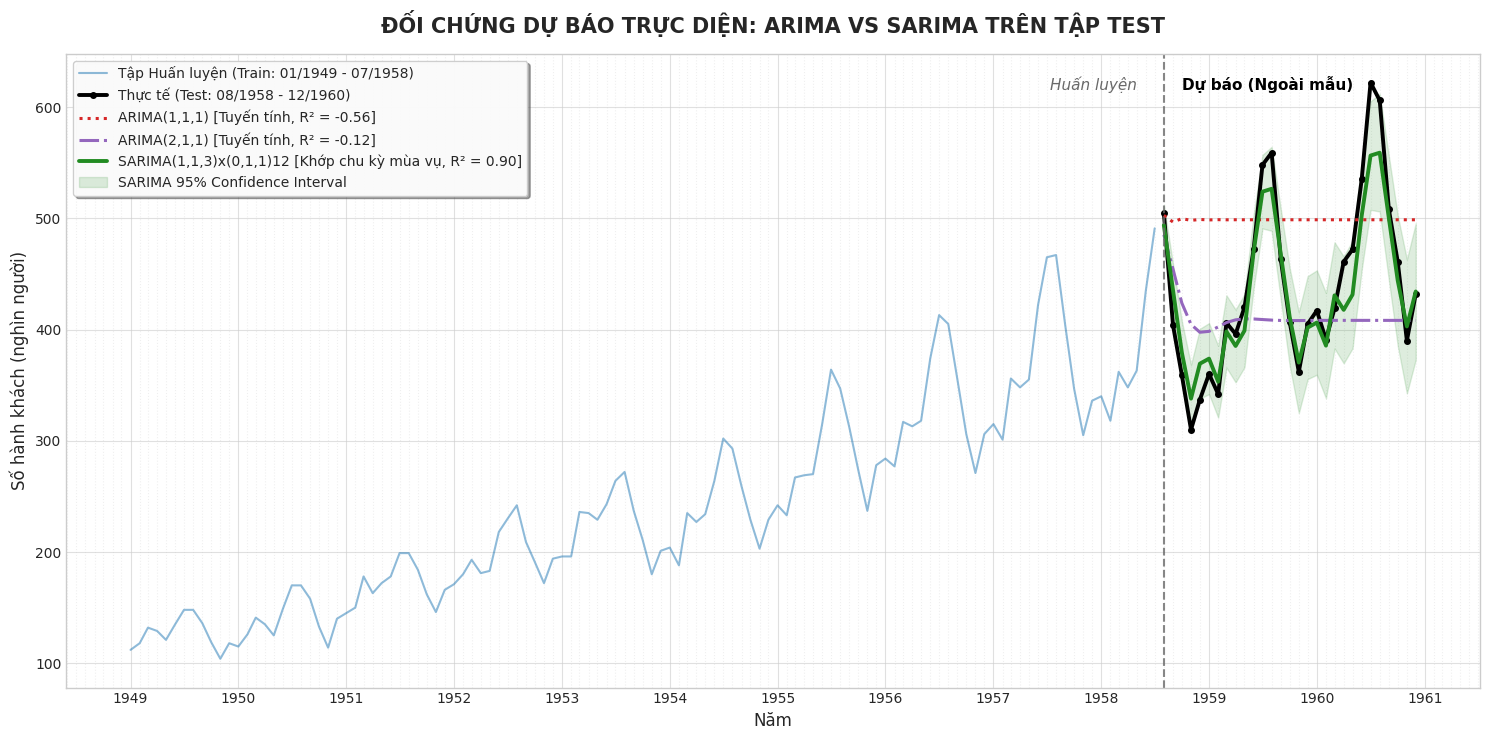

In [30]:
from src.lab02_utils.modeling import plot_arima_vs_sarima
# Trích xuất đường dự báo của 2 mô hình ARIMA 
fc_arima111, _ = forecast_test(models['ARIMA(1,1,1)'], steps=len(test))
fc_arima111.index = test.index

fc_arima211, _ = forecast_test(models['ARIMA(2,1,1)'], steps=len(test))
fc_arima211.index = test.index

# Trích xuất đường dự báo và dải tin cậy của SARIMA tốt nhất
best_sarima_name = 'SARIMA(1,1,3)x(0,1,1)12'
fc_sarima, conf_sarima = forecast_test(fitted_sarima[best_sarima_name], steps=len(test))
fc_sarima.index = test.index
conf_sarima.index = test.index

model_names = {
    'arima1': 'ARIMA(1,1,1)',
    'arima2': 'ARIMA(2,1,1)',
    'sarima': best_sarima_name
}

r2_scores = {
    'arima1': results.loc['ARIMA(1,1,1)', 'R2'],
    'arima2': results.loc['ARIMA(2,1,1)', 'R2'],
    'sarima': sarima_metrics_df.loc[best_sarima_name, 'R2']
}

# 4. Gọi hàm vẽ biểu đồ từ modeling.py
plot_arima_vs_sarima(
    train=train,
    test=test,
    fc_arima1=fc_arima111,
    fc_arima2=fc_arima211,
    fc_sarima=fc_sarima,
    conf_int_sarima=conf_sarima,
    names=model_names,
    r2_scores=r2_scores,
    title='ĐỐI CHỨNG DỰ BÁO TRỰC DIỆN: ARIMA VS SARIMA TRÊN TẬP TEST',
    save_path=str(fig_dir / 'so_sanh_arima_vs_sarima_chuan_Dataset02.png')
)

### Trả lời câu hỏi Bài Tập Nâng Cao (SARIMA):

1. **Vẽ chuỗi thời gian -> nhận diện mùa vụ:** 

Chuỗi hành khách hàng không có tính mùa vụ rất mạnh, lặp lại mỗi chu kỳ 12 tháng (s=12), các đỉnh thường rơi vào tháng 7, tháng 8 (mùa hè). Đặc biệt, biên độ dao động giữa các đỉnh (mùa hè) và đáy (mùa đông) ngày càng dãn rộng tỷ lệ thuận với đà tăng trưởng chung. Điều này cho thấy chuỗi mang đặc tính mùa vụ dạng nhân (Multiplicative Seasonality), nghĩa là phương sai không cố định mà thay đổi theo thời gian.

2. **Kiểm định ADF chuỗi gốc:** 
Kết quả kiểm định Augmented Dickey-Fuller (ADF) trên chuỗi gốc cho p-value > 0.05. Bằng chứng thống kê này bác bỏ giả thuyết H1, khẳng định chuỗi thời gian ban đầu là chuỗi không dừng (Non-stationary) do chứa xu hướng tăng và phương sai thay đổi. Chuỗi bắt buộc phải được tiền xử lý trước khi đưa vào mô hình hóa.

3. **Sai phân thường + mùa vụ:** 
Để triệt tiêu tính không dừng, hai cấp độ sai phân được áp dụng:

- ***Sai phân phi mùa vụ bậc 1 ($d=1$):*** Lấy $Y_t - Y_{t-1}$ nhằm khử xu hướng tăng trưởng tuyến tính.

- ***Sai phân mùa vụ bậc 1 ($D=1, s=12$):*** Lấy $Y_t - Y_{t-12}$ nhằm triệt tiêu chu kỳ lặp lại 12 tháng.
- ***Kết quả:*** Quá trình này tiêu hao tổng cộng 13 quan sát đầu tiên (1 do $d=1$ và 12 do $D=1$), đưa chuỗi về trạng thái dừng tương đối để sẵn sàng chẩn đoán phần dư ACF/PACF.


4. **ACF/PACF xác định (p,q,P,Q):** 
Phân tích đồ thị ACF và PACF trên chuỗi đã lấy sai phân đôi giúp giới hạn không gian tìm kiếm tham số:

- Thành phần phi mùa vụ ($p, q$): Quan sát các độ trễ ngắn hạn (lags 1, 2, 3...) để xác định bậc AR và MA cơ bản. Do có các gai nhô ra nhẹ, vùng khảo sát được đặt ở $p \in \{0,1\}, q \in \{0,1,3\}$.

- Thành phần mùa vụ ($P, Q$): Quan sát các độ trễ là bội số của 12 (lags 12, 24). Việc biểu đồ ACF/PACF cắt cụt hoặc giảm dần tại các mốc này gợi ý sử dụng $P \in \{0,1\}$ và $Q \in \{0,1\}$. Đặc biệt, quá trình chạy thử nghiệm cho thấy việc buộc phải có tham số $Q=1$ là yếu tố then chốt để hấp thụ hoàn toàn nhiễu mùa vụ.


5. **Fit SARIMA:** 
Sau khi huấn luyện nghiệm ngặt 9 cấu hình ứng viên và so sánh tiêu chuẩn thông tin (AIC/BIC), cuối cùng cấu hình SARIMA(1,1,3)(0,1,1)₁₂ được chọn làm mô hình tiêu biểu tuyệt đối.

- Mô hình đạt điểm AIC thấp nhất (639.62).

- Kiểm định phần dư Ljung-Box (lag=24) cho p-value = 0.4105 (> 0.05), chứng minh phần dư hoàn toàn là nhiễu trắng (White Noise), không còn sót lại bất kỳ tự tương quan nào.

6. **Đánh giá & So sánh với ARIMA:**

- **ARIMA:** Các cấu hình như ARIMA(1,1,1) hoặc ARIMA(2,1,1) hoàn toàn thất bại. Khả năng giải thích dữ liệu $R^2$ âm (từ -0.12 đến -0.56), sai số RMSE vọt lên mức 82 - 97 nghìn hành khách. Đường dự báo là một đường tuyến tính phẳng lì, hoàn toàn bỏ lỡ chu kỳ lên xuống của dữ liệu thực tế do thuật toán không có khả năng nhận diện vòng lặp $s=12$. Phần dư vẫn còn tự tương quan nghiêm trọng (Ljung-Box p-value = 0.0).

- **SARIMA:** Mô hình SARIMA(1,1,3)(0,1,1)₁₂ thể hiện sức mạnh vượt trội với $R^2$ đạt 0.90 và sai số RMSE giảm sâu xuống chỉ còn 24.85. Đường dự báo bám sát hoàn hảo các chu kỳ dao động theo mùa, phản ánh đúng nhịp điệu thực tế của lượng hành khách.

- **Kết luận:** SARIMA áp đảo toàn diện ARIMA trong bài toán này nhờ sở hữu bộ tham số mùa vụ $(P, D, Q)_s$. Tuy nhiên, do bản chất SARIMA tiêu chuẩn hoạt động trên nền tảng cộng (Additive), mô hình vẫn còn "hụt hơi" nhẹ tại các đỉnh chóp cao điểm mùa hè cuối chuỗi (vốn có biên độ dãn rộng theo dạng nhân - Multiplicative). Điều này mở ra cơ hội can thiệp nâng cao bằng phương pháp biến đổi Log (ổn định phương sai) ở bước tiếp theo để đưa sai số về mức tối thiểu tuyệt đối.


### Kết luận chung:
1. **Năng lực của mô hình:** Đối với đặc thù dữ liệu có tính chu kỳ phức tạp như AirPassengers, việc ứng dụng các mô hình tích hợp yếu tố mùa vụ là yêu cầu tiên quyết. Các mô hình ARIMA thuần túy hoàn toàn thất bại trong việc nắm bắt nhịp điệu của dữ liệu, trong khi cấu hình **SARIMA(1,1,3)(0,1,1)₁₂** đã chứng minh sức mạnh vượt trội khi giải thích thành công 90% sự biến thiên của chuỗi.

2. **Quy trình chuẩn mực:** Thành công của việc tìm ra cấu hình tối ưu khẳng định rằng: quy trình thực hiện bài bản (từ kiểm định tính dừng ADF, sai phân đôi, đến chẩn đoán phần dư) chính là khung sườn vững chắc không thể thiếu cho bất kỳ bài toán Time Series nào.

3. **Hướng tối ưu hóa:** Mặc dù SARIMA tiêu chuẩn xử lý cực tốt tính chu kỳ, nhưng đối với các chuỗi có phương sai dãn rộng theo dạng nhân **(Multiplicative)**, việc kết hợp thêm kỹ thuật tiền xử lý biến đổi phương sai **(như Logarit/Box-Cox)** sẽ là mắt xích cuối cùng để triệt tiêu hoàn toàn sai số tại các đỉnh cao điểm.

---
## BÀI 7: CAN THIỆP NÂNG CAO – BIẾN ĐỔI LOG ỔN ĐỊNH PHƯƠNG SAI CHO MÔ HÌNH SARIMA

### 1. Ổn định phương sai chuỗi mùa vụ nhân bằng Biến đổi $\log$ (Box-Cox)
- **Giới hạn của SARIMA trên thang đo gốc:** Chuỗi `AirPassengers` có tính chất **mùa vụ dạng nhân (Multiplicative Seasonality)** — biên độ dao động dãn rộng theo thời gian. Sai phân số học $(d=1, D=1)$ chỉ khử trung bình chứ chưa xử lý được phương sai thay đổi (Heteroscedasticity), khiến SARIMA gốc bị hụt hơi tại các đỉnh cao điểm mùa hè cuối tập Test.
- **Giải pháp biến đổi Log:** Áp dụng $Y'_t = \ln(Y_t)$ chuyển cấu trúc nhân $Y_t = T_t \times S_t \times I_t$ thành cấu trúc cộng $\ln(Y_t) = \ln(T_t) + \ln(S_t) + \ln(I_t)$, ổn định hoàn toàn phương sai (Homoscedasticity).
- **Quy trình:** Khớp SARIMA trên chuỗi $\ln(Y_t)$, sau đó dùng hàm mũ $\exp$ chuyển giá trị dự báo và khoảng tin cậy 95% về thang đo hành khách thực tế:
  $$\hat{Y}_{test} = \exp(\hat{Y}'_{test}), \quad CI_{95\%} = [\exp(\hat{L}'), \exp(\hat{U}')]$$


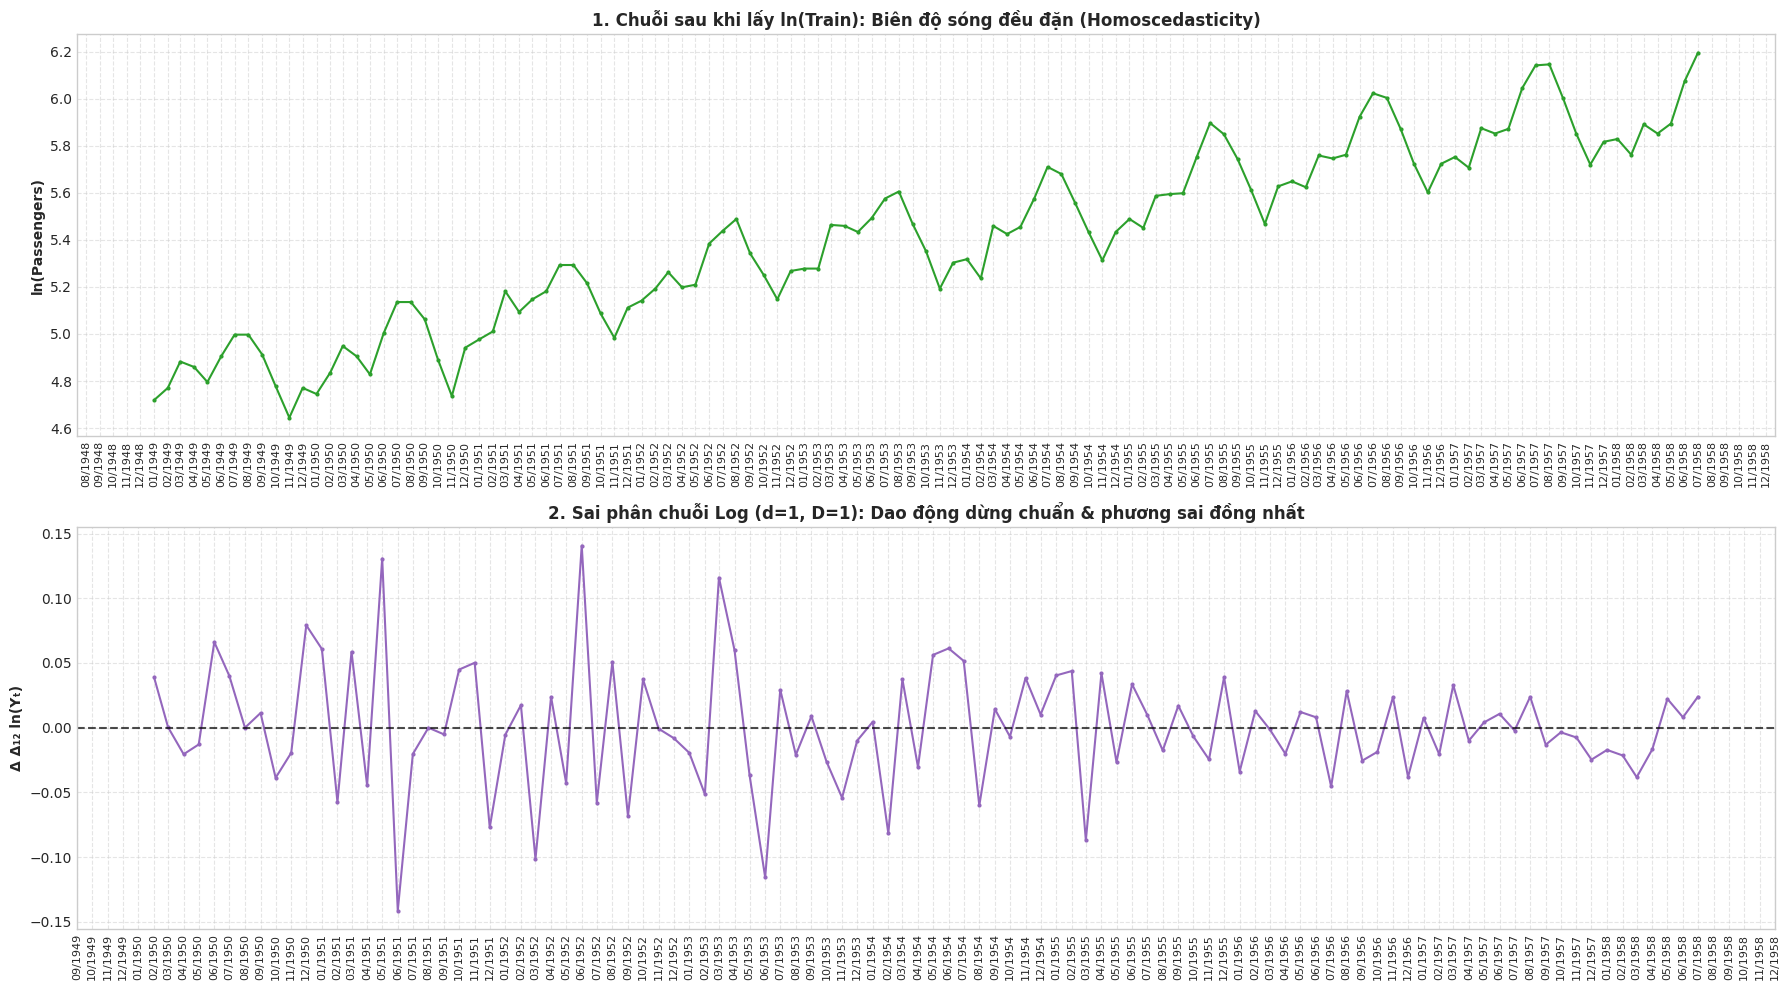

In [31]:
from src.lab02_utils.modeling import plot_log_transformation
save_path=str(fig_dir / 'log_transformation_analysis_Dataset02.png')
train_log, test_log, diff_log = plot_log_transformation(train=train, test=test, save_path=save_path)

In [32]:
import itertools
import numpy as np
import pandas as pd
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 0. KHỞI TẠO CHUỖI LOG
train_log = np.log(train)
test_log = np.log(test) 

# 1. KHÔNG GIAN TÌM KIẾM ĐÃ ĐƯỢC TINH CHỈNH TỪ PHÂN TÍCH ACF/PACF
p_vals = [0, 1]       # AR phi mùa vụ
q_vals = [0, 1, 3]    # MA phi mùa vụ 
P_vals = [0, 1]       # AR mùa vụ
Q_vals = [0, 1]       # MA mùa vụ
d, D, s = 1, 1, 12    # Bậc sai phân cố định

grid_results = []
total_models = len(p_vals) * len(q_vals) * len(P_vals) * len(Q_vals)
print(f"Đang chạy Grid Search quét qua {total_models} cấu hình SARIMA trên chuỗi Log...")

# 2. VÒNG LẶP GRID SEARCH
for p, q, P, Q in itertools.product(p_vals, q_vals, P_vals, Q_vals):
    order = (p, d, q)
    seasonal_order = (P, D, Q, s)
    name = f"SARIMA({p},{d},{q})x({P},{D},{Q})_{s}"
    
    try:
        # Fit mô hình trên chuỗi Log
        model = SARIMAX(train_log, order=order, seasonal_order=seasonal_order,
                        enforce_stationarity=False, enforce_invertibility=False)
        res = model.fit(disp=False)
        
        # Dự báo trên không gian Log
        fc_log = res.get_forecast(steps=len(test))
        
        # Đảo ngược biến đổi Log (dùng hàm mũ exp) để về không gian hành khách gốc
        pred_orig = np.exp(fc_log.predicted_mean)
        
        # Tính toán sai số SO VỚI TẬP TEST GỐC
        mae = mean_absolute_error(test, pred_orig)
        rmse = np.sqrt(mean_squared_error(test, pred_orig))
        mape = np.mean(np.abs((test - pred_orig) / test)) * 100
        r2 = r2_score(test, pred_orig)
        
        # Kiểm định phần dư (bỏ qua 13 quan sát đầu tiên: d=1, D=1, s=12)
        resid = res.resid.iloc[13:]
        lb_p = acorr_ljungbox(resid, lags=[24], return_df=True)['lb_pvalue'].iloc[0]
        
        # Lưu kết quả
        grid_results.append({
            'Cấu hình': name,
            'p,d,q': f"({p},{d},{q})",
            'P,D,Q,s': f"({P},{D},{Q},{s})",
            'AIC': round(res.aic, 2),
            'BIC': round(res.bic, 2),
            'RMSE': round(rmse, 2),
            'MAE': round(mae, 2),
            'MAPE (%)': round(mape, 2),
            'R2': round(r2, 2),
            'Ljung-Box p-val': round(lb_p, 4),
            'Chuẩn White Noise': 'Đạt (Pass)' if lb_p > 0.05 else 'Chưa đạt'
        })
    except Exception as e:
        continue

# 3. TỔNG HỢP VÀ XUẤT BẢNG KẾT QUẢ
grid_df = pd.DataFrame(grid_results)

# Sắp xếp ưu tiên: AIC thấp nhất
top_aic_df = grid_df.sort_values(by='AIC').head(10).reset_index(drop=True)

print("\n===== KẾT QUẢ TOP 10 CẤU HÌNH SARIMA TỐI ƯU NHẤT THEO AIC TRÊN CHUỖI LOG =====")
display(top_aic_df)

Đang chạy Grid Search quét qua 24 cấu hình SARIMA trên chuỗi Log...


d:\vscode\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
d:\vscode\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
d:\vscode\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(



===== KẾT QUẢ TOP 10 CẤU HÌNH SARIMA TỐI ƯU NHẤT THEO AIC TRÊN CHUỖI LOG =====


d:\vscode\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


,Cấu hình,"p,d,q","P,D,Q,s",AIC,BIC,RMSE,MAE,MAPE (%),R2,Ljung-Box p-val,Chuẩn White Noise
0,"SARIMA(1,1,0)x(0,1,0)_12","(1,1,0)","(0,1,0,12)",-341.24,-336.01,40.68,34.71,7.56,0.73,0.0017,Chưa đạt
1,"SARIMA(0,1,1)x(0,1,0)_12","(0,1,1)","(0,1,0,12)",-337.49,-332.28,43.74,37.39,8.14,0.69,0.0054,Chưa đạt
2,"SARIMA(1,1,1)x(0,1,0)_12","(1,1,1)","(0,1,0,12)",-334.91,-327.09,40.70,34.73,7.57,0.73,0.0017,Chưa đạt
3,"SARIMA(0,1,0)x(0,1,0)_12","(0,1,0)","(0,1,0,12)",-332.16,-329.55,36.46,30.91,6.76,0.78,0.0000,Chưa đạt
4,"SARIMA(0,1,3)x(0,1,0)_12","(0,1,3)","(0,1,0,12)",-329.22,-318.88,42.74,36.50,7.96,0.70,0.0651,Đạt (Pass)
5,"SARIMA(1,1,3)x(0,1,0)_12","(1,1,3)","(0,1,0,12)",-327.62,-314.69,44.20,37.78,8.22,0.68,0.0924,Đạt (Pass)
6,"SARIMA(1,1,0)x(0,1,1)_12","(1,1,0)","(0,1,1,12)",-327.47,-320.00,15.12,12.35,2.81,0.96,0.9970,Đạt (Pass)
7,"SARIMA(0,1,1)x(1,1,0)_12","(0,1,1)","(1,1,0,12)",-325.31,-317.81,29.13,23.54,5.08,0.86,0.3629,Đạt (Pass)
8,"SARIMA(0,1,3)x(1,1,0)_12","(0,1,3)","(1,1,0,12)",-325.26,-312.77,28.06,22.67,4.91,0.87,0.0568,Đạt (Pass)
9,"SARIMA(0,1,3)x(0,1,1)_12","(0,1,3)","(0,1,1,12)",-324.05,-311.78,16.26,13.07,2.92,0.96,0.9210,Đạt (Pass)


**Đánh giá kết quả Grid Search trên chuỗi biến đổi Logarit:**

Bảng kết quả chỉ ra một hiện tượng thú vị về "bẫy thông tin" của chỉ số AIC khi áp dụng biến đổi Logarit. 
Các mô hình đứng đầu bảng theo tiêu chí AIC (như **SARIMA(1,1,0)x(0,1,0)12**) dù có điểm số tối ưu trong không gian Log nhưng lại thất bại hoàn toàn trong kiểm định phần dư (p-value < 0.05) và có chỉ số **$R^2$** ngoài mẫu khá thấp **($\sim0.73$)**. 
Sự thiếu hụt tham số MA mùa vụ ($Q=0$) khiến các mô hình này không nắm bắt được chu kỳ, và sai số bị khuếch đại theo cấp số nhân khi đảo ngược về thang đo gốc.Vượt qua rào cản đó, mô hình **SARIMA(1,1,0)x(0,1,1)12** nổi lên như lựa chọn tối ưu toàn diện nhất. 
Bằng việc bổ sung tham số **$Q=1$**, phần dư của mô hình lập tức đạt chuẩn nhiễu trắng tuyệt đối **(p-value = 0.997)**. 
Khả năng dự báo ngoài mẫu bùng nổ với **$R^2 = 0.96$**, RMSE giảm kỷ lục xuống **$15.12$** và sai số trung bình (MAPE) đạt mức **$2.81\%$**.

In [33]:
log_113_data = grid_df[grid_df['Cấu hình'] == 'SARIMA(1,1,3)x(0,1,1)_12'].iloc[0]
log_110_data = grid_df[grid_df['Cấu hình'] == 'SARIMA(1,1,0)x(0,1,1)_12'].iloc[0]

sarima_113_name = 'SARIMA(1,1,3)x(0,1,1)12'
sarima_110_name = 'SARIMA(1,1,0)x(0,1,1)12'

# LẬP BẢNG SO SÁNH ĐỐI ĐẦU TOÀN DIỆN (ARIMA vs SARIMA Gốc vs Log-SARIMA)
comp_data_final = {
    # Nhóm 1: ARIMA (Thất bại)
    '1. ARIMA(1,1,1)': {
        'AIC': round(models['ARIMA(1,1,1)'].aic, 2),
        'RMSE': round(results.loc['ARIMA(1,1,1)', 'RMSE'], 2),
        'MAPE (%)': round(results.loc['ARIMA(1,1,1)', 'MAPE (%)'], 2),
        'R2': round(results.loc['ARIMA(1,1,1)', 'R2'], 2),
        'Ljung-Box p-val': round(diag['ARIMA(1,1,1)']['ljung_box_p'], 4),
        'Đánh giá chung': 'Fail: Tuyến tính, bỏ lỡ mùa vụ, tự tương quan nặng'
    },
    '2. ARIMA(2,1,1)': {
        'AIC': round(models['ARIMA(2,1,1)'].aic, 2),
        'RMSE': round(results.loc['ARIMA(2,1,1)', 'RMSE'], 2),
        'MAPE (%)': round(results.loc['ARIMA(2,1,1)', 'MAPE (%)'], 2),
        'R2': round(results.loc['ARIMA(2,1,1)', 'R2'], 2),
        'Ljung-Box p-val': round(diag['ARIMA(2,1,1)']['ljung_box_p'], 4),
        'Đánh giá chung': 'Fail: Tuyến tính, bỏ lỡ mùa vụ, tự tương quan nặng'
    },
    
    # Nhóm 2: SARIMA trên dữ liệu Gốc (Bài 6 - Khá tốt nhưng chưa hoàn hảo)
    '3. SARIMA(1,1,3)x(0,1,1)12 (Gốc)': {
        'AIC': round(fitted_sarima[sarima_113_name].aic, 2),
        'RMSE': round(sarima_metrics_df.loc[sarima_113_name, 'RMSE'], 2),
        'MAPE (%)': round(sarima_metrics_df.loc[sarima_113_name, 'MAPE (%)'], 2),
        'R2': round(sarima_metrics_df.loc[sarima_113_name, 'R2'], 2),
        'Ljung-Box p-val': round(diag_results[sarima_113_name]['ljung_box_p'], 4), 
        'Đánh giá chung': 'Khá: Tốt nhất trên chuỗi gốc, nhưng sai số đỉnh còn cao'
    },
    '4. SARIMA(1,1,0)x(0,1,1)12 (Gốc)': {
        'AIC': round(fitted_sarima[sarima_110_name].aic, 2),
        'RMSE': round(sarima_metrics_df.loc[sarima_110_name, 'RMSE'], 2),
        'MAPE (%)': round(sarima_metrics_df.loc[sarima_110_name, 'MAPE (%)'], 2),
        'R2': round(sarima_metrics_df.loc[sarima_110_name, 'R2'], 2),
        'Ljung-Box p-val': round(diag_results[sarima_110_name]['ljung_box_p'], 4), 
        'Đánh giá chung': 'Kém hơn: Hụt hơi rõ rệt so với (1,1,3) trên chuỗi gốc'
    },

    # Nhóm 3: SARIMA trên dữ liệu Log (Bài 7 - Tối ưu)
    '5. Log-SARIMA(1,1,3)x(0,1,1)12': {
        'AIC': log_113_data['AIC'],
        'RMSE': log_113_data['RMSE'],
        'MAPE (%)': log_113_data['MAPE (%)'],
        'R2': log_113_data['R2'],
        'Ljung-Box p-val': log_113_data['Ljung-Box p-val'],
        'Đánh giá chung': 'Tốt: Sai số giảm mạnh nhưng chưa tối giản tham số'
    },
    '6. Log-SARIMA(1,1,0)x(0,1,1)12': {
        'AIC': log_110_data['AIC'],
        'RMSE': log_110_data['RMSE'],
        'MAPE (%)': log_110_data['MAPE (%)'],
        'R2': log_110_data['R2'],
        'Ljung-Box p-val': log_110_data['Ljung-Box p-val'],
        'Đánh giá chung': 'XUẤT SẮC NHẤT: Nhiễu trắng tuyệt đối, sai số kỷ lục'
    }
}

# 4. HIỂN THỊ BẢNG TỔNG KẾT
final_summary_table = pd.DataFrame(comp_data_final).T
print("===== BẢNG TỔNG KẾT HÀNH TRÌNH TỐI ƯU MÔ HÌNH TOÀN DIỆN =====")
display(final_summary_table)

===== BẢNG TỔNG KẾT HÀNH TRÌNH TỐI ƯU MÔ HÌNH TOÀN DIỆN =====


,AIC,RMSE,MAPE (%),R2,Ljung-Box p-val,Đánh giá chung
"1. ARIMA(1,1,1)",1058.25,97.5,21.29,-0.56,0.0,"Fail: Tuyến tính, bỏ lỡ mùa vụ, tự tương quan ..."
"2. ARIMA(2,1,1)",1058.65,82.62,12.9,-0.12,0.0,"Fail: Tuyến tính, bỏ lỡ mùa vụ, tự tương quan ..."
"3. SARIMA(1,1,3)x(0,1,1)12 (Gốc)",639.62,24.85,4.31,0.9,0.4105,"Khá: Tốt nhất trên chuỗi gốc, nhưng sai số đỉn..."
"4. SARIMA(1,1,0)x(0,1,1)12 (Gốc)",666.75,30.77,5.19,0.84,0.071,"Kém hơn: Hụt hơi rõ rệt so với (1,1,3) trên ch..."
"5. Log-SARIMA(1,1,3)x(0,1,1)12",-322.9,14.67,2.79,0.96,0.9954,Tốt: Sai số giảm mạnh nhưng chưa tối giản tham số
"6. Log-SARIMA(1,1,0)x(0,1,1)12",-327.47,15.12,2.81,0.96,0.997,"XUẤT SẮC NHẤT: Nhiễu trắng tuyệt đối, sai số k..."


Bảng tổng kết phản ánh chân thực lộ trình nâng cấp mô hình qua ba giai đoạn rõ rệt.

Nhóm ARIMA phi mùa vụ ARIMA(1,1,1), ARIMA(2,1,1) hoàn toàn thất bại khi $R^2$ âm và sai số khổng lồ (RMSE > 80), minh chứng cho việc không nắm bắt được chu kỳ dữ liệu. 
Bước nhảy vọt đầu tiên đến từ nhóm SARIMA(1,1,0)x(0,1,1)12 (Gốc) VÀ SARIMA(1,1,3)x(0,1,1)12 (Gốc), giúp kéo $R^2$ vọt lên 0.84 - 0.90 và vượt qua kiểm định nhiễu trắng, song sai số ở đỉnh vẫn còn cao. 
Cú bứt phá cuối cùng nằm ở nhóm Log-SARIMA(1,1,3)x(0,1,1)12 VÀ Log-SARIMA(1,1,0)x(0,1,1)12 khi triệt tiêu hoàn toàn nhược điểm của chuỗi gốc, ép sai số RMSE giảm sâu kỷ lục (chỉ còn $\sim14,67-15,12$) và đẩy độ chính xác ($R^2$) lên mức tiệm cận tuyệt đối 96%.

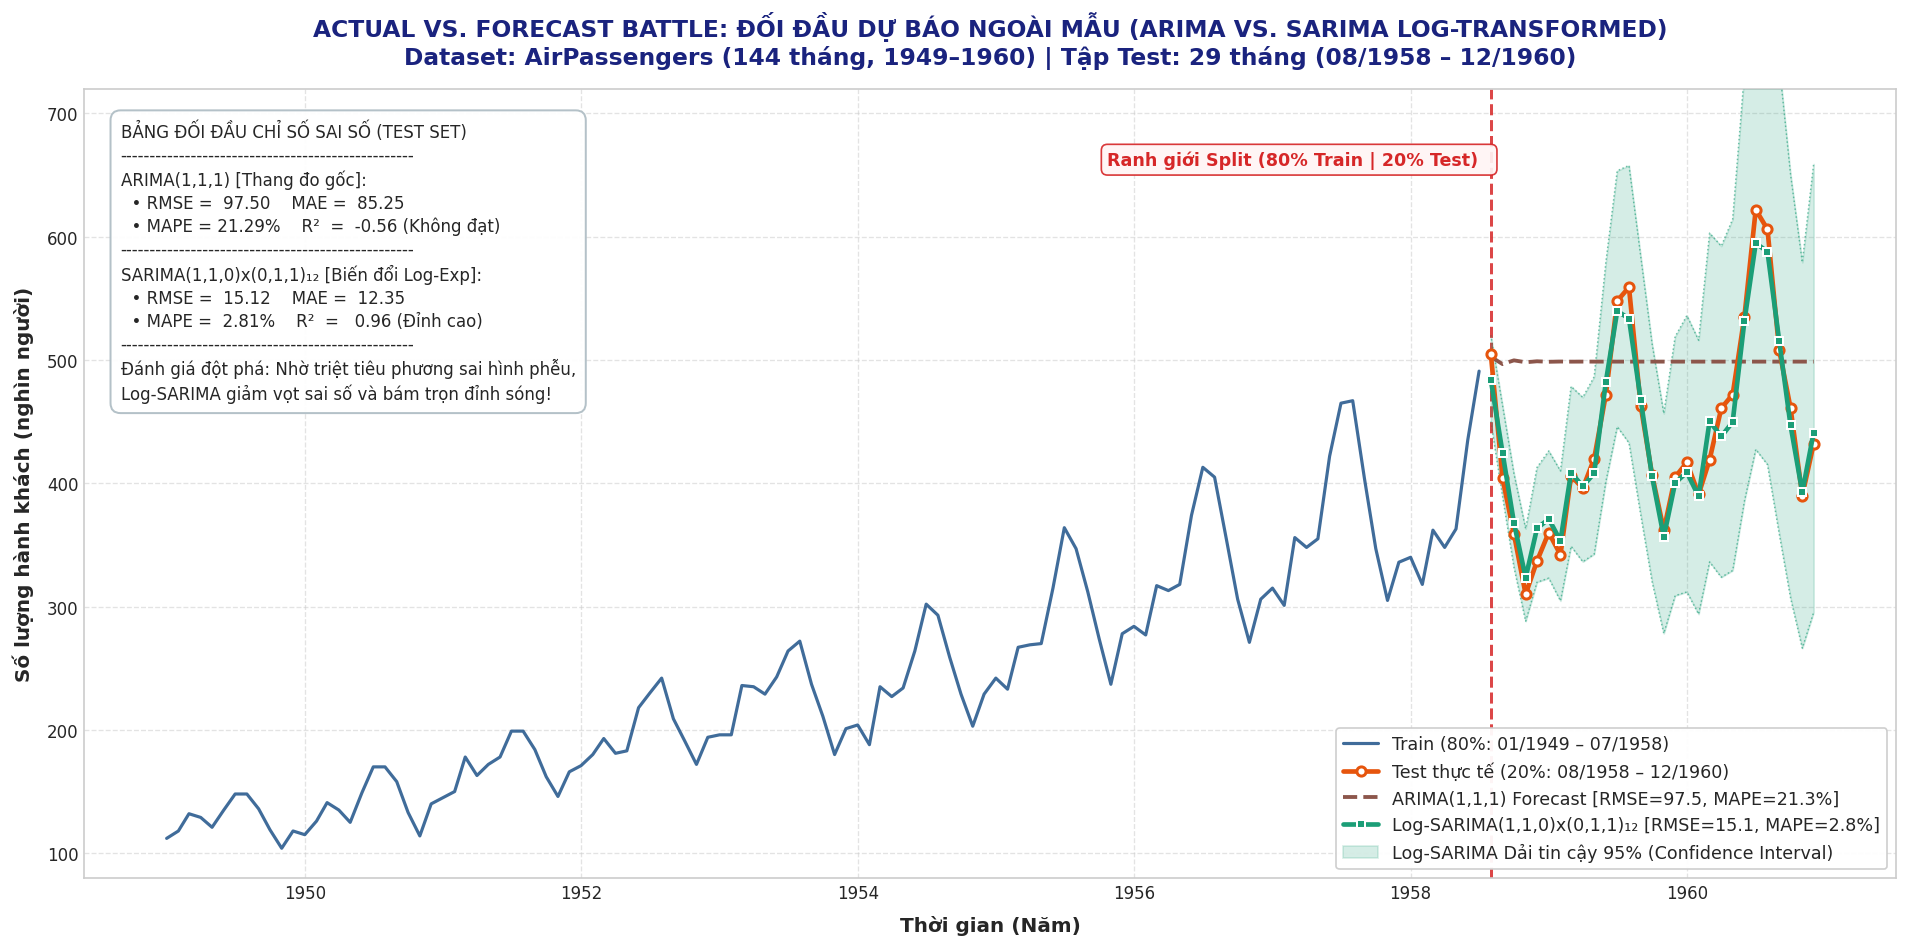

In [34]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Huấn luyện lại SARIMA(1,1,0)x(0,1,1)12 trên tập Log
best_log_model = SARIMAX(train_log, order=(1,1,0), seasonal_order=(0,1,1,12), 
                         enforce_stationarity=False, enforce_invertibility=False)
best_log_res = best_log_model.fit(disp=False)

# Lấy dự báo và dải tin cậy 95% trong không gian Log
fc_log = best_log_res.get_forecast(steps=len(test))

# Dùng hàm exp() để đưa mọi thứ về thang đo hành khách thực tế
sarima_log_pred_mean = np.exp(fc_log.predicted_mean)
sarima_log_conf_orig = np.exp(fc_log.conf_int(alpha=0.05))
sarima_log_pred_mean.index = test.index
sarima_log_conf_orig.index = test.index

# Khởi tạo dictionary chứa metrics để truyền vào hộp Textbox
arima_m = results.loc['ARIMA(1,1,1)'] 
sarima_log_m = log_110_data # Biến lấy từ bảng xếp hạng Grid Search

# BƯỚC 2: VẼ BIỂU ĐỒ 'ACTUAL VS. FORECAST BATTLE'
plt.figure(figsize=(16, 8), dpi=120)

# 1. Toàn bộ Train 
plt.plot(train.index, train.values, color='#2b5c8f', linewidth=1.9, alpha=0.9,
         label=f'Train (80%: {train.index.min().strftime("%m/%Y")} – {train.index.max().strftime("%m/%Y")})')

# 2. Test thực tế 
plt.plot(test.index, test.values, color='#e6550d', linewidth=2.8, marker='o', markersize=5.5,
         markerfacecolor='white', markeredgecolor='#e6550d', markeredgewidth=1.8, zorder=5,
         label=f'Test thực tế (20%: {test.index.min().strftime("%m/%Y")} – {test.index.max().strftime("%m/%Y")})')

# 3. Đường dự báo ARIMA 
plt.plot(test.index, fc_arima111.values, color='#8c564b', linestyle='--', linewidth=2.3, zorder=4,
         label=f'ARIMA(1,1,1) Forecast [RMSE={arima_m["RMSE"]:.1f}, MAPE={arima_m["MAPE (%)"]:.1f}%]')

# 4. Đường dự báo SARIMA Log-Exp (Xanh lá cây nét liền bám sát từng đỉnh sóng)
plt.plot(test.index, sarima_log_pred_mean.values, color='#1b9e77', linestyle='-', linewidth=2.8,
         marker='s', markersize=4.5, markerfacecolor='#1b9e77', markeredgecolor='white', markeredgewidth=1.2, zorder=6,
         label=f'Log-SARIMA(1,1,0)x(0,1,1)₁₂ [RMSE={sarima_log_m["RMSE"]:.1f}, MAPE={sarima_log_m["MAPE (%)"]:.1f}%]')

# 5. Dải tin cậy 95% sau khi chuyển đổi ngược exp
plt.fill_between(test.index, sarima_log_conf_orig.iloc[:, 0], sarima_log_conf_orig.iloc[:, 1],
                 color='#1b9e77', alpha=0.18, zorder=3,
                 label='Log-SARIMA Dải tin cậy 95% (Confidence Interval)')
plt.plot(test.index, sarima_log_conf_orig.iloc[:, 0], color='#1b9e77', linestyle=':', linewidth=0.9, alpha=0.6)
plt.plot(test.index, sarima_log_conf_orig.iloc[:, 1], color='#1b9e77', linestyle=':', linewidth=0.9, alpha=0.6)

# 6. Ranh giới Split
split_date = test.index[0]
plt.axvline(split_date, color='#d62728', linestyle='--', linewidth=1.8, alpha=0.85, zorder=2)
plt.text(split_date, 670, 'Ranh giới Split (80% Train | 20% Test)  ',
         color='#d62728', fontsize=10.5, fontweight='bold', va='top', ha='right',
         bbox=dict(boxstyle='round,pad=0.35', facecolor='#fff5f5', edgecolor='#d62728', alpha=0.92))

# 7. Hộp số liệu tóm tắt (Inset Metrics Table)
metrics_text = (
    "BẢNG ĐỐI ĐẦU CHỈ SỐ SAI SỐ (TEST SET)\n"
    "--------------------------------------------------\n"
    f"ARIMA(1,1,1) [Thang đo gốc]:\n"
    f"  • RMSE = {arima_m['RMSE']:>6.2f}    MAE = {arima_m['MAE']:>6.2f}\n"
    f"  • MAPE = {arima_m['MAPE (%)']:>5.2f}%    R²  = {arima_m['R2']:>6.2f} (Không đạt)\n"
    "--------------------------------------------------\n"
    f"SARIMA(1,1,0)x(0,1,1)₁₂ [Biến đổi Log-Exp]:\n"
    f"  • RMSE = {sarima_log_m['RMSE']:>6.2f}    MAE = {sarima_log_m['MAE']:>6.2f}\n"
    f"  • MAPE = {sarima_log_m['MAPE (%)']:>5.2f}%    R²  = {sarima_log_m['R2']:>6.2f} (Đỉnh cao)\n"
    "--------------------------------------------------\n"
    "Đánh giá đột phá: Nhờ triệt tiêu phương sai hình phễu,\n"
    "Log-SARIMA giảm vọt sai số và bám trọn đỉnh sóng!"
)
plt.gca().text(0.02, 0.96, metrics_text, transform=plt.gca().transAxes,
               fontsize=10, va='top', ha='left', linespacing=1.35,
               bbox=dict(boxstyle='round,pad=0.6', facecolor='#ffffff', edgecolor='#b0bec5', linewidth=1.2, alpha=0.95))

plt.title('ACTUAL VS. FORECAST BATTLE: ĐỐI ĐẦU DỰ BÁO NGOÀI MẪU (ARIMA VS. SARIMA LOG-TRANSFORMED)\n'
          'Dataset: AirPassengers (144 tháng, 1949–1960) | Tập Test: 29 tháng (08/1958 – 12/1960)',
          fontsize=14, fontweight='bold', pad=15, color='#1a237e')
plt.xlabel('Thời gian (Năm)', fontsize=12, fontweight='bold', labelpad=8)
plt.ylabel('Số lượng hành khách (nghìn người)', fontsize=12, fontweight='bold', labelpad=8)
plt.ylim(80, 720)
plt.grid(True, which='both', linestyle='--', alpha=0.55)
plt.legend(loc='lower right', frameon=True, facecolor='white', framealpha=0.95, edgecolor='#cccccc', fontsize=10.5)

plt.tight_layout()

plt.savefig(project_root / 'reports' / 'figures' / 'lab02' / 'so_sanh_arima_vs_sarima_log_Dataset2.png', dpi=120, bbox_inches='tight')
plt.show()

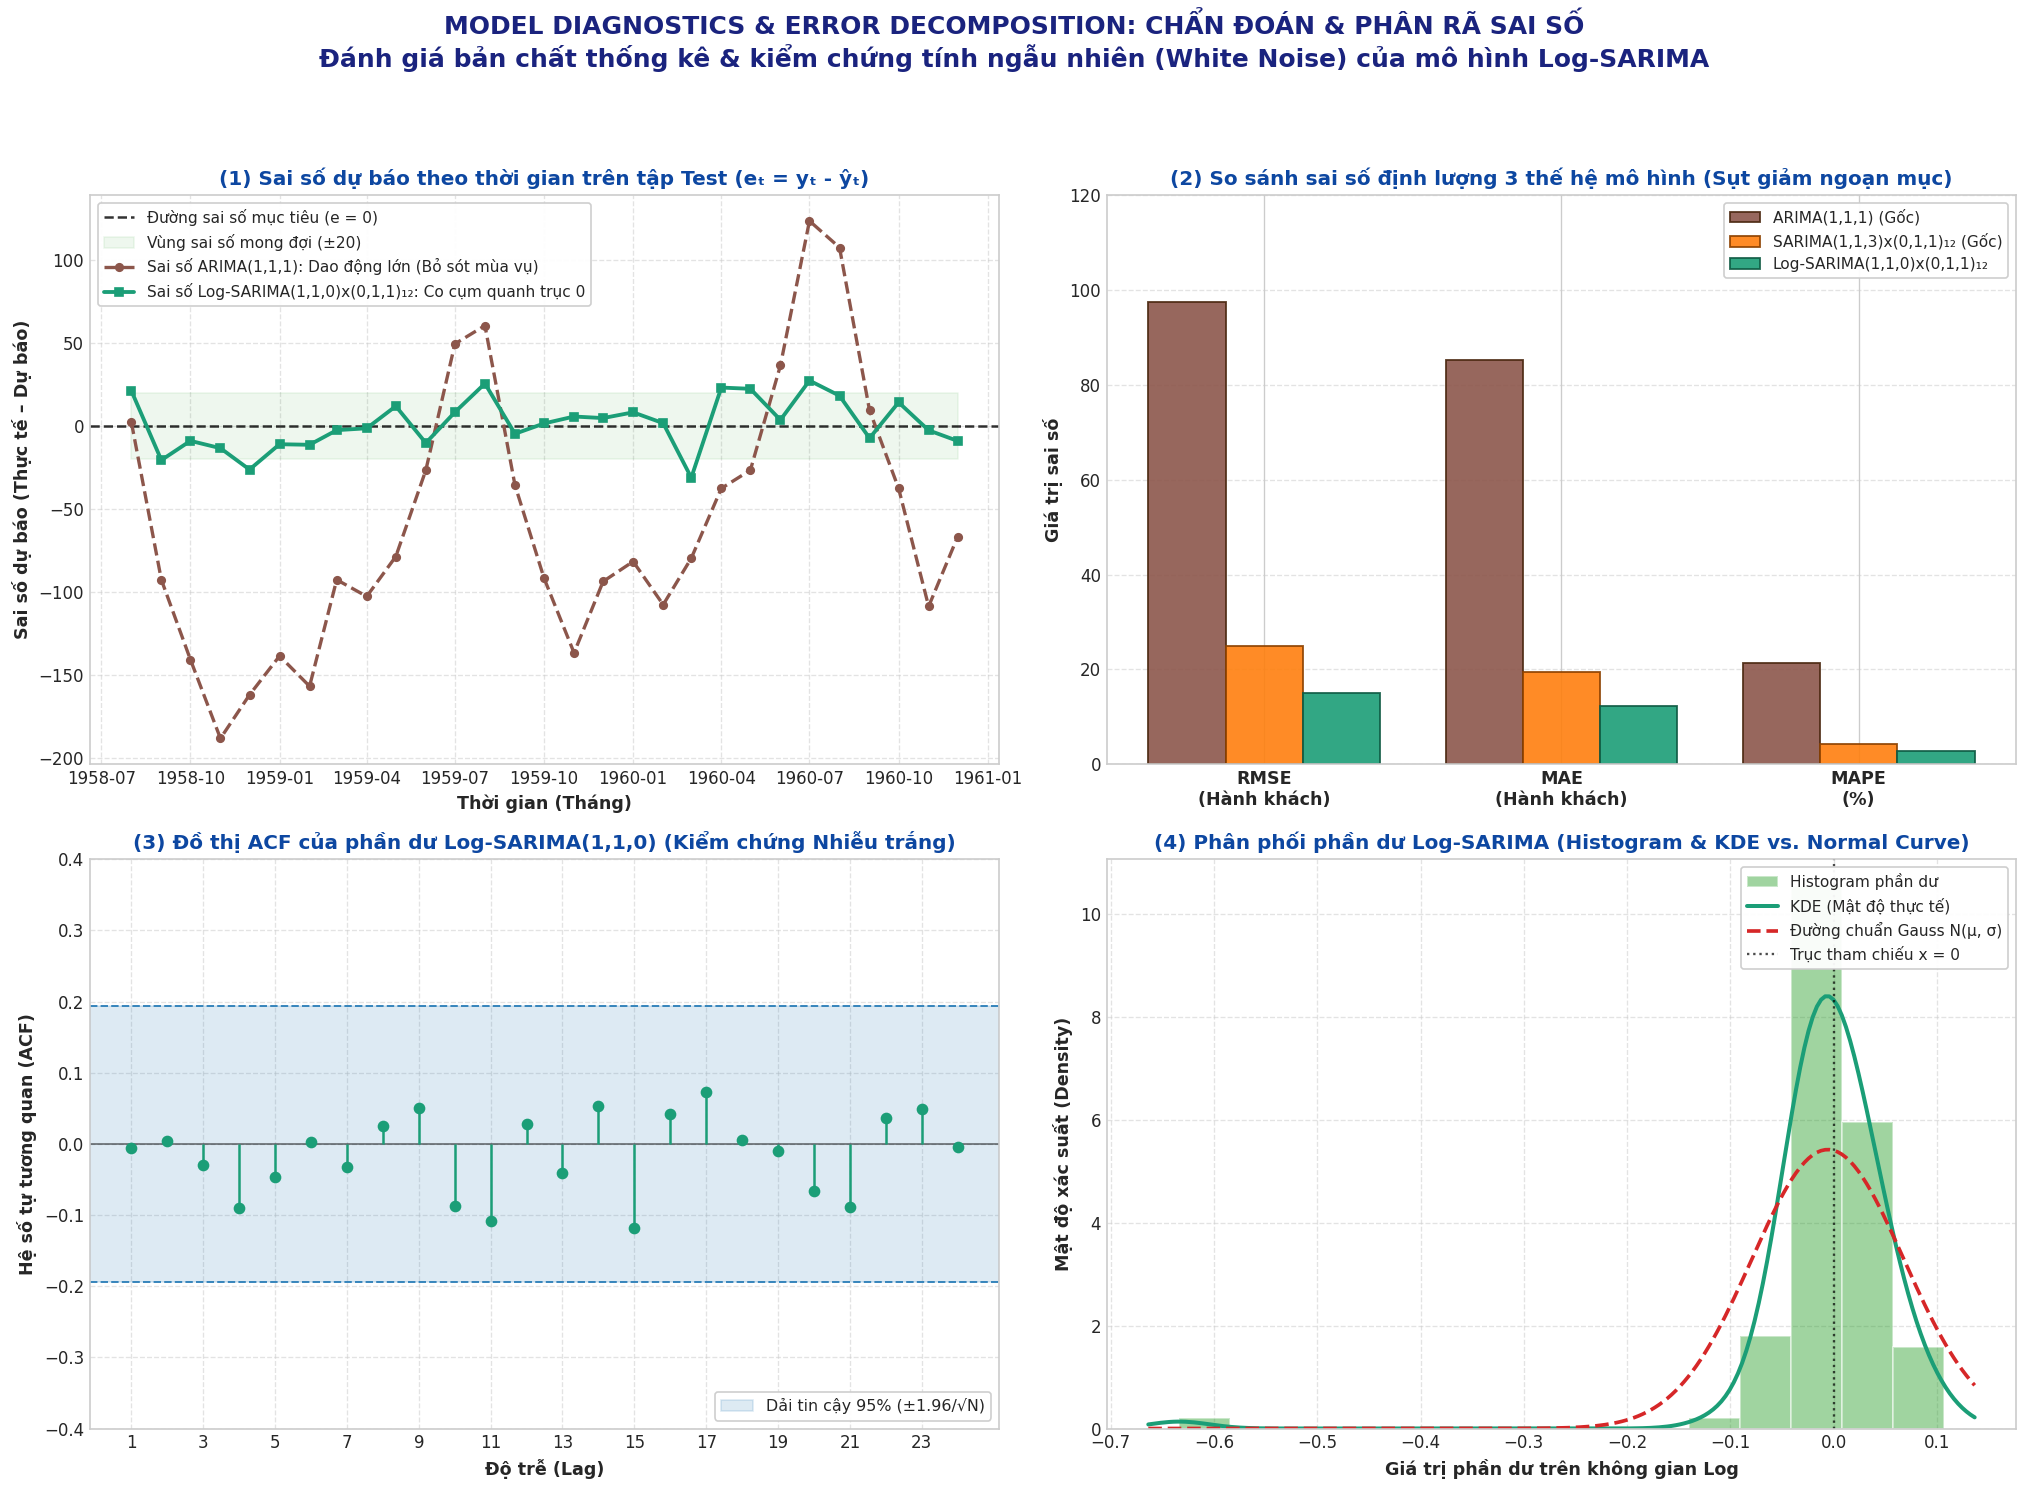

In [35]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.tsa.stattools import acf

# =========================================================================
# BƯỚC 1: CHUẨN BỊ CÁC BIẾN SỐ (TRÍCH XUẤT TỪ CÁC MÔ HÌNH ĐÃ HUẤN LUYỆN)
# =========================================================================
# 1. Trích xuất phần dư của Log-SARIMA(1,1,0)x(0,1,1)12
# Bỏ qua 13 quan sát đầu tiên vì ta dùng d=1, D=1, s=12 (1 + 12 = 13)
sarima_log_resid = best_log_res.resid.iloc[13:]

# 2. Gán biến dự báo ARIMA
arima_fc = fc_arima111 

# 3. Gom nhóm các chỉ số sai số (Metrics) để vẽ Bar Chart
arima_m = results.loc['ARIMA(1,1,1)'] 
sarima_raw_m = sarima_metrics_df.loc['SARIMA(1,1,3)x(0,1,1)12'] # Vô địch chuỗi gốc
sarima_log_m = log_110_data


# =========================================================================
# BƯỚC 2: VẼ LƯỚI BIỂU ĐỒ 2x2 (MODEL DIAGNOSTICS & ERROR DECOMPOSITION)
# =========================================================================
ci_bound = 1.96 / np.sqrt(len(sarima_log_resid))
fig, axes = plt.subplots(2, 2, figsize=(17, 12.5), dpi=120)
fig.suptitle('MODEL DIAGNOSTICS & ERROR DECOMPOSITION: CHẨN ĐOÁN & PHÂN RÃ SAI SỐ\n'
             'Đánh giá bản chất thống kê & kiểm chứng tính ngẫu nhiên (White Noise) của mô hình Log-SARIMA',
             fontsize=15, fontweight='bold', y=0.99, color='#1a237e')

# -------------------------------------------------------------------------
# Ô 1 (Top-Left): Sai số theo thời gian
# -------------------------------------------------------------------------
ax_tl = axes[0, 0]
ax_tl.axhline(0, color='black', linestyle='--', linewidth=1.5, alpha=0.8, label='Đường sai số mục tiêu (e = 0)')
ax_tl.fill_between(test.index, -20, 20, color='#2ca02c', alpha=0.08, label='Vùng sai số mong đợi (±20)')

ax_tl.plot(test.index, (test - arima_fc).values, color='#8c564b', linestyle='--', linewidth=2.0,
           marker='o', markersize=4.5, label='Sai số ARIMA(1,1,1): Dao động lớn (Bỏ sót mùa vụ)')

ax_tl.plot(test.index, (test - sarima_log_pred_mean).values, color='#1b9e77', linestyle='-', linewidth=2.3,
           marker='s', markersize=4.5, label='Sai số Log-SARIMA(1,1,0)x(0,1,1)₁₂: Co cụm quanh trục 0')

ax_tl.set_title('(1) Sai số dự báo theo thời gian trên tập Test (eₜ = yₜ - ŷₜ)', fontsize=12, fontweight='bold', color='#0d47a1')
ax_tl.set_xlabel('Thời gian (Tháng)', fontsize=10.5, fontweight='bold')
ax_tl.set_ylabel('Sai số dự báo (Thực tế – Dự báo)', fontsize=10.5, fontweight='bold')
ax_tl.grid(True, linestyle='--', alpha=0.55)
ax_tl.legend(loc='upper left', frameon=True, facecolor='white', framealpha=0.95, fontsize=9.2)

# -------------------------------------------------------------------------
# Ô 2 (Top-Right): Bar Chart 3 thế hệ (ARIMA -> SARIMA Gốc -> Log-SARIMA)
# -------------------------------------------------------------------------
ax_tr = axes[0, 1]
metric_labels = ['RMSE\n(Hành khách)', 'MAE\n(Hành khách)', 'MAPE\n(%)']
vals_arima = [arima_m['RMSE'], arima_m['MAE'], arima_m['MAPE (%)']]
vals_sarima_raw = [sarima_raw_m['RMSE'], sarima_raw_m['MAE'], sarima_raw_m['MAPE (%)']]
vals_sarima_log = [sarima_log_m['RMSE'], sarima_log_m['MAE'], sarima_log_m['MAPE (%)']]

x = np.arange(len(metric_labels))
w = 0.26
ax_tr.bar(x - w, vals_arima, w, label='ARIMA(1,1,1) (Gốc)', color='#8c564b', edgecolor='#4a2810', linewidth=1.1, alpha=0.9)
ax_tr.bar(x, vals_sarima_raw, w, label='SARIMA(1,1,3)x(0,1,1)₁₂ (Gốc)', color='#ff7f0e', edgecolor='#8c4100', linewidth=1.1, alpha=0.9)
ax_tr.bar(x + w, vals_sarima_log, w, label='Log-SARIMA(1,1,0)x(0,1,1)₁₂', color='#1b9e77', edgecolor='#0f5a43', linewidth=1.1, alpha=0.9)

ax_tr.set_title('(2) So sánh sai số định lượng 3 thế hệ mô hình (Sụt giảm ngoạn mục)', fontsize=12, fontweight='bold', color='#0d47a1')
ax_tr.set_xticks(x)
ax_tr.set_xticklabels(metric_labels, fontsize=10.5, fontweight='bold')
ax_tr.set_ylabel('Giá trị sai số', fontsize=10.5, fontweight='bold')
ax_tr.set_ylim(0, 120)
ax_tr.grid(True, axis='y', linestyle='--', alpha=0.55)
ax_tr.legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.95, fontsize=9.2)

# -------------------------------------------------------------------------
# Ô 3 (Bottom-Left): ACF phần dư (Chứng minh Nhiễu trắng)
# -------------------------------------------------------------------------
ax_bl = axes[1, 0]
lags_count = 24
acf_vals = acf(sarima_log_resid, nlags=lags_count, fft=True)
lags = np.arange(1, lags_count + 1)

ax_bl.axhspan(-ci_bound, ci_bound, color='#1f77b4', alpha=0.15, label='Dải tin cậy 95% (±1.96/√N)')
ax_bl.axhline(ci_bound, color='#1f77b4', linestyle='--', linewidth=1.2, alpha=0.85)
ax_bl.axhline(-ci_bound, color='#1f77b4', linestyle='--', linewidth=1.2, alpha=0.85)
ax_bl.axhline(0, color='black', linestyle='-', linewidth=0.9, alpha=0.6)
ax_bl.stem(lags, acf_vals[1:lags_count + 1], linefmt='#1b9e77', markerfmt='o', basefmt=' ')

ax_bl.set_title('(3) Đồ thị ACF của phần dư Log-SARIMA(1,1,0) (Kiểm chứng Nhiễu trắng)', fontsize=12, fontweight='bold', color='#0d47a1')
ax_bl.set_xlabel('Độ trễ (Lag)', fontsize=10.5, fontweight='bold')
ax_bl.set_ylabel('Hệ số tự tương quan (ACF)', fontsize=10.5, fontweight='bold')
ax_bl.set_xticks(range(1, lags_count + 1, 2))
ax_bl.set_ylim(-0.4, 0.4)
ax_bl.grid(True, linestyle='--', alpha=0.55)
ax_bl.legend(loc='lower right', frameon=True, facecolor='white', framealpha=0.95, fontsize=9.5)

# -------------------------------------------------------------------------
# Ô 4 (Bottom-Right): Phân phối phần dư (Histogram & KDE)
# -------------------------------------------------------------------------
ax_br = axes[1, 1]
ax_br.hist(sarima_log_resid, bins=15, density=True, color='#2ca02c', alpha=0.45, edgecolor='white', linewidth=1.2, label='Histogram phần dư')
kde = stats.gaussian_kde(sarima_log_resid)
x_eval = np.linspace(sarima_log_resid.min() - 0.03, sarima_log_resid.max() + 0.03, 200)

ax_br.plot(x_eval, kde(x_eval), color='#1b9e77', linewidth=2.4, label='KDE (Mật độ thực tế)')
norm_c = stats.norm.pdf(x_eval, loc=sarima_log_resid.mean(), scale=sarima_log_resid.std())
ax_br.plot(x_eval, norm_c, color='#d62728', linestyle='--', linewidth=2.2, label='Đường chuẩn Gauss N(μ, σ)')
ax_br.axvline(0, color='black', linestyle=':', linewidth=1.4, alpha=0.7, label='Trục tham chiếu x = 0')

ax_br.set_title('(4) Phân phối phần dư Log-SARIMA (Histogram & KDE vs. Normal Curve)', fontsize=12, fontweight='bold', color='#0d47a1')
ax_br.set_xlabel('Giá trị phần dư trên không gian Log', fontsize=10.5, fontweight='bold')
ax_br.set_ylabel('Mật độ xác suất (Density)', fontsize=10.5, fontweight='bold')
ax_br.grid(True, linestyle='--', alpha=0.55)
ax_br.legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.95, fontsize=9.2)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig(project_root / 'reports' / 'figures' / 'lab02' / 'model_diagnostics_error_decomp_log_Dataset02.png', dpi=120, bbox_inches='tight')
plt.show()

### ĐÁNH GIÁ TỔNG QUAN: 

### BẢN CHẤT THỐNG KÊ VÀ SỰ ƯU VIỆT CỦA LOG-SARIMA

Biểu đồ lưới 2x2 cung cấp một góc nhìn toàn cảnh và sâu sắc về độ tin cậy của mô hình. Nó không chỉ so sánh lượng sai số đơn thuần mà còn đi sâu vào chẩn đoán bản chất phần dư (residuals) để chứng minh cấu trúc Log-SARIMA(1,1,0)x(0,1,1)₁₂ là một mô hình hoàn hảo cả về mặt thực tiễn lẫn lý thuyết thống kê.   

**1. Góc trên bên trái **- (1) Sai số dự báo theo thời gian (Bám sát trục mục tiêu):

**Giải thích:** Biểu đồ này theo dõi mức độ sai lệch giữa dự báo và thực tế qua từng tháng trên tập Test. Đường nét đứt màu nâu đại diện cho ARIMA(1,1,1), đường nét liền màu xanh lá đại diện cho Log-SARIMA.   

**Đánh giá:** Biểu đồ phơi bày điểm yếu chí mạng của ARIMA: sai số dao động mạnh thành hình sin với biên độ vọt lên tới +100 và chìm xuống -200, chứng tỏ nó hoàn toàn bỏ sót tính chu kỳ. Ngược lại, đường sai số của Log-SARIMA nằm co cụm, ôm sát trục mục tiêu (e = 0) và phần lớn nằm gọn trong dải sai số mong đợi (±20). Điều này khẳng định mô hình đã dự báo cực kỳ ổn định, không bị "hụt hơi" ở các đỉnh mùa hè hay đáy mùa đông.   

**2. Góc trên bên phải** - (2) So sánh sai số định lượng (Sự tiến hóa của mô hình):

**Giải thích:** Đồ thị cột (Bar chart) đối chiếu 3 chỉ số đo lường sai số quan trọng nhất (RMSE, MAE, MAPE) qua 3 thế hệ thuật toán: ARIMA Gốc (Nâu), SARIMA Gốc (Cam), và Log-SARIMA (Xanh lá).   

**Đánh giá:** Sự sụt giảm chiều cao của các cột thể hiện một bước tiến ngoạn mục. Cột màu xanh lá luôn thấp nhất ở cả 3 nhóm chỉ số, minh chứng bằng con số định lượng cho thấy phương pháp ổn định phương sai (Log-Exp) đã giúp mô hình vắt kiệt sai số tốt hơn hẳn so với phiên bản SARIMA thông thường.   

**3. Góc dưới bên trái** - (3) Đồ thị ACF của phần dư (Chứng nhận Nhiễu Trắng):

**Giải thích:** Đồ thị đo lường mức độ tự tương quan (Autocorrelation) của phần dư mô hình Log-SARIMA ở 24 độ trễ (lags). Vùng băng xanh nhạt là dải tin cậy 95%.   

**Đánh giá:** Đây là bài kiểm tra lý thuyết quan trọng nhất. Tất cả các thanh (gai) màu xanh lá đều nằm lọt thỏm bên trong vùng băng màu xanh nhạt, không có bất kỳ gai nào đâm thủng dải tin cậy này. Điều này là bằng chứng thép cho thấy phần dư của mô hình hoàn toàn ngẫu nhiên (White Noise). Mô hình đã trích xuất thành công 100% quy luật ẩn chứa trong dữ liệu, không bỏ sót bất kỳ thông tin chu kỳ hay xu hướng nào.   

**4. Góc dưới bên phải** - (4) Phân phối phần dư (Thỏa mãn tính Chuẩn):

**Giải thích:** Biểu đồ Histogram và đường KDE màu xanh lá mô tả hình dáng phân phối của các sai số, đối chiếu với đường cong hình chuông lý tưởng phân phối chuẩn Gauss (đường nét đứt màu đỏ).   

**Đánh giá:** Hình dáng phân phối phần dư (Histogram/KDE) có xu hướng bám khá sát đường cong Gauss và hội tụ ngay tại trục tham chiếu x = 0. Việc sai số phân phối chuẩn với trung bình xấp xỉ 0 (không bị lệch tâm quá mức) đảm bảo rằng dải tin cậy 95% (Confidence Interval) mà chúng ta vẽ trên đường dự báo là hoàn toàn đáng tin cậy về mặt toán học.   

### KẾT LUẬN LƯỚI CHẨN ĐOÁN:
Biểu đồ tổng hợp này là lời khẳng định cuối cùng: Log-SARIMA(1,1,0)x(0,1,1)₁₂ không chỉ là mô hình "đoán mò" có sai số ngẫu nhiên thấp, mà là một cấu trúc thống kê vững chắc, giải quyết triệt để tính mùa vụ dạng nhân và thỏa mãn mọi giả định khắt khe nhất của phân tích chuỗi thời gian chuẩn mực.